In [1]:
!pip install xarray netcdf4 h5netcdf

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import xarray as xr
import pandas as pd
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
sciezka = "./Pobieranie_danych_drugim_sposobem_dla_9_panstw/era5_output/"
pliki = glob.glob(sciezka + "*.nc")

print("Liczba plików:", len(pliki))
print(pliki[:5])

Liczba plików: 36
['./Pobieranie_danych_drugim_sposobem_dla_9_panstw/era5_output\\era5_francja_lyon.nc', './Pobieranie_danych_drugim_sposobem_dla_9_panstw/era5_output\\era5_francja_nice.nc', './Pobieranie_danych_drugim_sposobem_dla_9_panstw/era5_output\\era5_francja_paris.nc', './Pobieranie_danych_drugim_sposobem_dla_9_panstw/era5_output\\era5_francja_toulouse.nc', './Pobieranie_danych_drugim_sposobem_dla_9_panstw/era5_output\\era5_grecja_athens.nc']


Wczytanie plików .nc

In [4]:
sciezka = "./Pobieranie_danych_drugim_sposobem_dla_9_panstw/era5_output/"

pliki = glob.glob(os.path.join(sciezka, "*.nc"))

dane_panstwa = {}

for plik in pliki:
    nazwa = os.path.basename(plik).replace(".nc", "")
    
    ds = xr.open_dataset(plik)
    df = ds.to_dataframe().reset_index()
    
    czesci = nazwa.split("_")
    kraj = czesci[1]
    miasto = "_".join(czesci[2:])
    
    df["kraj"] = kraj
    df["miasto"] = miasto
    
    if kraj not in dane_panstwa:
        dane_panstwa[kraj] = []
    
    dane_panstwa[kraj].append(df)
    
    ds.close()


for kraj in dane_panstwa:
    dane_panstwa[kraj] = pd.concat(dane_panstwa[kraj], ignore_index=True)


df_polska = dane_panstwa.get("polska")
df_francja = dane_panstwa.get("francja")
df_hiszpania = dane_panstwa.get("hiszpania")
df_norwegia = dane_panstwa.get("norwegia")
df_rumunia = dane_panstwa.get("rumunia")
df_turcja = dane_panstwa.get("turcja")
df_wegry = dane_panstwa.get("wegry")
df_wlochy = dane_panstwa.get("wlochy")
df_grecja = dane_panstwa.get("grecja")

print("Dane wczytane do DataFrame.")

Dane wczytane do DataFrame.


Konwersja temperatury z Kelwinów na Celcjusze, opady z metrów na milimetry oraz mamy składowe na wiatr (info z dokumentacji o zmiennych: https://cds.climate.copernicus.eu/datasets/derived-era5-single-levels-daily-statistics?tab=overview ). O zmiennej dotyczącej opadów jest informacja, że dany rekord to opad skumulowany w dnaym kroku czasowym - mamy dane godzinowe więc jest to opad w danej godzinie. 

Stworzono zmienną temp_dew_diff mówiącą o różnicy temp i punktu rosy -> wskaźnik o suchości powietrza. Jak duży to bardzo sucho, jak mały to wilgotno. Humidity to wilgotność względna.

Zauważono wiele braków w kolumnie opady - wynika to z tego, że wtedy wogóle nie padało - uzupełniamy zerami. 


In [5]:
df_wlochy.head()

,valid_time,u10,v10,d2m,t2m,tp,latitude,longitude,kraj,miasto
0,1940-01-01 00:00:00,0.843079,0.734467,263.759583,271.047913,NaN,44.5,11.25,wlochy,bologna
1,1940-01-01 01:00:00,0.378403,1.677551,263.727112,270.522583,NaN,44.5,11.25,wlochy,bologna
2,1940-01-01 02:00:00,-0.088364,0.198380,263.710602,270.200989,NaN,44.5,11.25,wlochy,bologna
3,1940-01-01 03:00:00,-0.256088,-0.278824,263.944000,270.224976,NaN,44.5,11.25,wlochy,bologna
4,1940-01-01 04:00:00,0.237045,-0.734360,263.794067,269.973907,NaN,44.5,11.25,wlochy,bologna


In [6]:
lista_df = [
    df_polska, df_francja, df_hiszpania, df_norwegia,
    df_rumunia, df_turcja, df_wegry, df_wlochy, df_grecja
]

for df in lista_df:
    df["valid_time"] = pd.to_datetime(df["valid_time"])
    df["tp"] = df["tp"].fillna(0)
    df["temp_C"] = df["t2m"] - 273.15
    df["dewpoint_C"] = df["d2m"] - 273.15
    df["tp_mm"] = df["tp"] * 1000
    df["wind_speed"] = np.sqrt(df["u10"]**2 + df["v10"]**2)
    # różnica temp - dew point 
    df["temp_dew_diff"] = df["temp_C"] - df["dewpoint_C"]
    
    # wilgotność względna
    df["humidity"] = 100 * (
        np.exp((17.625 * df["dewpoint_C"]) / (243.04 + df["dewpoint_C"])) /
        np.exp((17.625 * df["temp_C"]) / (243.04 + df["temp_C"]))
    )

In [7]:
df_wegry.head()

,valid_time,u10,v10,d2m,t2m,tp,latitude,longitude,kraj,miasto,temp_C,dewpoint_C,tp_mm,wind_speed,temp_dew_diff,humidity
0,1940-01-01 00:00:00,0.894836,2.259857,254.060364,266.842834,0.0,47.5,19.0,wegry,budapest,-6.307159,-19.089630,0.0,2.430573,12.782471,35.601280
1,1940-01-01 01:00:00,1.141098,2.266418,254.445877,266.719849,0.0,47.5,19.0,wegry,budapest,-6.430145,-18.704117,0.0,2.537471,12.273972,37.138592
2,1940-01-01 02:00:00,1.242691,2.323380,254.862946,266.097473,0.0,47.5,19.0,wegry,budapest,-7.052521,-18.287048,0.0,2.634838,11.234528,40.359863
3,1940-01-01 03:00:00,1.330826,1.961411,255.225250,265.150757,0.0,47.5,19.0,wegry,budapest,-7.999237,-17.924744,0.0,2.370280,9.925507,44.773788
4,1940-01-01 04:00:00,1.494858,1.442398,255.296021,264.710236,0.0,47.5,19.0,wegry,budapest,-8.439758,-17.853973,0.0,2.077285,9.414215,46.610443


Sprawdzam braki danych.

In [8]:
for name, df in zip(
    ["polska","francja","hiszpania","norwegia","rumunia","turcja","wegry","wlochy","grecja"],
    lista_df
):
    print("----", name, "----")
    print(df.isna().sum())
    print()

---- polska ----
valid_time       0
u10              0
v10              0
d2m              0
t2m              0
tp               0
latitude         0
longitude        0
kraj             0
miasto           0
temp_C           0
dewpoint_C       0
tp_mm            0
wind_speed       0
temp_dew_diff    0
humidity         0
dtype: int64

---- francja ----
valid_time       0
u10              0
v10              0
d2m              0
t2m              0
tp               0
latitude         0
longitude        0
kraj             0
miasto           0
temp_C           0
dewpoint_C       0
tp_mm            0
wind_speed       0
temp_dew_diff    0
humidity         0
dtype: int64

---- hiszpania ----
valid_time       0
u10              0
v10              0
d2m              0
t2m              0
tp               0
latitude         0
longitude        0
kraj             0
miasto           0
temp_C           0
dewpoint_C       0
tp_mm            0
wind_speed       0
temp_dew_diff    0
humidity         0
dtype

Po wyeliminowaniu braków w kolumnie z opadami (typ braków - MNAR - nie było danych bo nie padało - przyczynowo - skutkowy) nie ma innych NaN.

**Sprawdzenie duplikatów**

In [9]:
for name, df in zip(
    ["polska","francja","hiszpania","norwegia","rumunia","turcja","wegry","wlochy","grecja"],
    lista_df
):
    print(name, "duplikaty:", df.duplicated().sum())

polska duplikaty: 0
francja duplikaty: 0
hiszpania duplikaty: 0
norwegia duplikaty: 0
rumunia duplikaty: 0
turcja duplikaty: 0
wegry duplikaty: 0
wlochy duplikaty: 0
grecja duplikaty: 0


Nie zidentyfikowaną żadnych duplikatów na poziomie całych wierszy.

**Sprawdzenie statystyki na poziomie Państw & Sprawdzenie zakresów wartości - czy nie ma jakiś oulierów**

In [10]:
for name, df in zip(
    ["polska","francja","hiszpania","norwegia","rumunia","turcja","wegry","wlochy","grecja"],
    lista_df
):
    print("---- Podstawowe statystyki", name, "----")
    print(df[[
        "temp_C",
        "dewpoint_C",
        "humidity",
        "temp_dew_diff",
        "tp_mm",
        "wind_speed"
    ]].describe().round(2))
    print()

---- Podstawowe statystyki polska ----
           temp_C  dewpoint_C    humidity  temp_dew_diff       tp_mm  \
count  3023712.00  3023712.00  3023712.00     3023712.00  3023712.00   
mean         8.31        4.40       78.53           3.91        0.08   
std          8.87        7.64       15.26           3.48        0.27   
min        -31.79      -34.12       11.78          -0.00        0.00   
25%          1.76       -0.65       69.61           1.44        0.00   
50%          8.32        4.79       82.53           2.74        0.00   
75%         14.97       10.43       90.41           5.32        0.03   
max         37.50       25.36      100.02          33.98       19.29   

       wind_speed  
count  3023712.00  
mean         3.62  
std          1.86  
min          0.00  
25%          2.21  
50%          3.33  
75%          4.72  
max         17.60  

---- Podstawowe statystyki francja ----
           temp_C  dewpoint_C    humidity  temp_dew_diff       tp_mm  \
count  3023712.00  

Na podstawie analizy statystyk opisowych dla zmiennych stwierdzono, że wartości w zbiorze danych mieszczą się w fizycznie możliwych zakresach i nie wskazują na błędy pomiarowe ani błędy przetwarzania danych.

Minimalne temperatury w analizowanych krajach wynosiły od około -36°C (Norwegia) do około -20°C (kraje południowej Europy), natomiast maksymalne temperatury wynosiły od około 33°C (Norwegia) do około 45°C (Turcja, Grecja, Hiszpania).
Wartości te są realistyczne dla klimatu europejskiego – bardzo niskie temperatury występują w Skandynawii, natomiast bardzo wysokie w krajach południowych w okresie letnim.

Średnie wartości temperatury punktu rosy były dodatnie dla większości krajów europejskich i wynosiły od około 0,8°C w Norwegii do około 10°C w Grecji i we Włoszech. Wyższe wartości temperatury punktu rosy występowały w krajach południowych, co wskazuje na większą wilgotność powietrza i cieplejszy klimat. W krajach północnych, takich jak Norwegia, wartości punktu rosy były znacznie niższe, co jest charakterystyczne dla chłodniejszego i bardziej wilgotnego klimatu.

Wilgotność względna powietrza w analizowanych krajach wynosiła średnio od około 66% w Turcji do około 79% w Norwegii. Wyższa wilgotność występowała w krajach północnych oraz nadmorskich, natomiast niższa w krajach południowych, takich jak Hiszpania, Grecja i Turcja, co jest zgodne z występowaniem bardziej suchego klimatu śródziemnomorskiego.

Różnica pomiędzy temperaturą powietrza a temperaturą punktu rosy (temp_dew_diff), będąca wskaźnikiem suchości powietrza, była najmniejsza w Norwegii (około 3,5°C), a największa w Turcji i Hiszpanii (około 7°C). Oznacza to, że powietrze w krajach południowych jest bardziej suche, natomiast w krajach północnych bardziej wilgotne. Wartości maksymalne tej zmiennej przekraczały 30–50°C, co odpowiada bardzo suchym masom powietrza i również mieści się w możliwych zakresach fizycznych.

Minimalna wartość opadów wynosiła 0 mm, co oznacza brak opadu i jest wartością poprawną.
Maksymalne wartości opadów wynosiły od około 9 mm do 27 mm na 1 godzinę, co odpowiada intensywnym opadom deszczu lub burzom i jest wartością realistyczną w danych meteorologicznych.

Minimalna prędkość wiatru wynosiła 0 m/s, co oznacza ciszę i jest wartością poprawną.
Maksymalne prędkości wiatru wynosiły około 12–20 m/s, co odpowiada silnemu wiatrowi lub wichurze i jest wartością realistyczną dla Europy, szczególnie w obszarach nadmorskich i górskich.

In [11]:
summary = []

for name, df in zip(
    ["polska","francja","hiszpania","norwegia","rumunia","turcja","wegry","wlochy","grecja"],
    lista_df
):
    summary.append([
        name,
        round(df["temp_C"].mean(), 2),
        round(df["dewpoint_C"].mean(), 2),
        round(df["humidity"].mean(), 2),
        round(df["temp_dew_diff"].mean(), 2),
        round(df["tp_mm"].mean(), 3),
        round(df["wind_speed"].mean(), 2),
        df["valid_time"].min(),
        df["valid_time"].max()
    ])

summary_df = pd.DataFrame(summary, columns=[
    "kraj",
    "srednia_temp_C",
    "sredni_dewpoint_C",
    "srednia_wilgotnosc_%", 
    "srednia_roznica_temp_dew_C",
    "sredni_opad_mm_h",
    "sredni_wiatr_m_s",
    "data_min",
    "data_max"
])

print(summary_df)

        kraj  srednia_temp_C  sredni_dewpoint_C  srednia_wilgotnosc_%  \
0     polska            8.31               4.40             78.529999   
1    francja           12.25               7.74             76.099998   
2  hiszpania           14.76               7.90             67.620003   
3   norwegia            4.25               0.77             79.459999   
4    rumunia           10.29               5.35             74.550003   
5     turcja           14.94               7.57             65.940002   
6      wegry           11.19               5.70             72.269997   
7     wlochy           14.79               9.64             73.739998   
8     grecja           16.33               9.99             69.739998   

   srednia_roznica_temp_dew_C  sredni_opad_mm_h  sredni_wiatr_m_s   data_min  \
0                        3.91             0.080              3.62 1940-01-01   
1                        4.50             0.098              2.88 1940-01-01   
2                        6.86

**Temperatura**

Najcieplejsze kraje: Grecja, Turcja, Hiszpania, Włochy

Najzimniejszy kraj: Norwegia

Polska, Rumunia, Węgry -> klimat kontynentalny/umiarkowany

**Opady**

Najwięcej opadów: Norwegia

Dużo opadów: Włochy, Francja

Mało opadów: Hiszpania, Grecja

**Wiatr**

Największy wiatr: Polska

Najmniejszy wiatr: Grecja

**Temperatura punktu rosy**

Najwyższe wratości: Grecja, Włochy

Najniższe: Norwegia

**Wilgotność względna**

Najwyższa: Norwegia, Polska

Najniższa: Turcja, Hiszpania

**Różnica między temperaturą a punktem rosy (wskaźnik suchości powietrza)**

Największa wartość: Turcja, Hiszpania

Najniższe wartości: Norwegia, Polska




Należy zauważyć, że temperatura punktu rosy była wyższa w krajach południowych, co oznacza większą zawartość pary wodnej w powietrzu. Jednocześnie wilgotność względna była wyższa w krajach północnych, co wynika z niższej temperatury powietrza. W niskich temperaturach powietrze może utrzymać mniejszą ilość pary wodnej, dlatego szybciej osiąga stan nasycenia, co powoduje wyższą wilgotność względną. W wysokich temperaturach powietrze może utrzymać więcej pary wodnej, dlatego mimo większej ilości wilgoci wilgotność względna jest niższa.

Mamy 86 lat danych godzinowych. 

**Sprawdzam statystyki na poziomie miast**

In [12]:
def statystyki_miasta(df, kraj):
    stats = df.groupby("miasto")[["temp_C",
        "dewpoint_C",
        "humidity",
        "temp_dew_diff",
        "tp_mm",
        "wind_speed"]].describe()
    print(f"Statystyki dla miast – {kraj}")
    display(stats)
    
    print("\nŚrednie wartości:")
    srednie = df.groupby("miasto")[["temp_C",
        "dewpoint_C",
        "humidity",
        "temp_dew_diff",
        "tp_mm",
        "wind_speed"]].mean()
    display(srednie.sort_values("temp_C", ascending=False))
    
    return srednie

In [13]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_rows', 200)
pd.set_option('display.float_format', '{:.3f}'.format)

In [14]:
srednie_polska = statystyki_miasta(df_polska, "Polska")

Statystyki dla miast – Polska


temp_C                                               dewpoint_C                                                  humidity                                                   temp_dew_diff                                                  tp_mm                                            wind_speed                                           
              count  mean   std     min   25%   50%    75%    max      count  mean   std     min    25%   50%    75%    max      count   mean    std    min    25%    50%    75%     max         count  mean   std    min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                        
gdansk   755928.000 8.032 8.391 -27.537 1.874 7.909 14.459 35.750 755928.000 4.425 7.389 -31.485 -0.415 4.675 10.319 23.214 755928.000 79.695 13.868 17.558 71.998 83.345 90.258 100.018    755928.000 3.606 3.059 -0.003 1.465 2.598 4.800 26.127 755928.000 0.074 0.260 0.000 0.000 0.001 0.027 11.839 755928.000 4.328 2.080 0.007 2.757 4.076 5.600 17.601
krakow   755928.000 8.126 9.161 -31.017 1.422 8.366 14.938 36.569 755928.000 4.289 7.991 -33.863 -1.165 4.711 10.713 23.991 755928.000 78.835 15.103 12.053 70.049 82.842 90.533 100.019    755928.000 3.837 3.403 -0.003 1.414 2.679 5.218 31.592 755928.000 0.094 0.296 0.000 0.000 0.000 0.048 12.475 755928.000 2.979 1.728 0.004 1.720 2.568 3.969 13.795
poznan   755928.000 8.680 8.695 -28.065 2.179 8.623 15.170 37.504 755928.000 4.616 7.294 -30.561 -0.203 5.027 10.272 25.355 755928.000 77.959 15.821 12.117 68.335 81.980 90.562 100.018    755928.000 4.064 3.644 -0.003 1.413 2.847 5.611 33.979 755928.000 0.073 0.264 0.000 0.000 0.000 0.026 19.292 755928.000 3.670 1.718 0.007 2.378 3.433 4.694 15.219
warszawa 755928.000 8.396 9.209 -31.788 1.538 8.378 15.356 36.347 755928.000 4.257 7.855 -34.119 -0.819 4.715 10.434 23.710 755928.000 77.616 16.085 11.780 67.959 81.783 90.321 100.018    755928.000 4.138 3.750 -0.003 1.448 2.863 5.671 30.589 755928.000 0.078 0.272 0.000 0.000 0.000 0.030 16.809 755928.000 3.496 1.636 0.002 2.265 3.266 4.464 14.065


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
poznan,8.680,4.616,77.959,4.064,0.073,3.670
warszawa,8.396,4.257,77.616,4.138,0.078,3.496
krakow,8.126,4.289,78.835,3.837,0.094,2.979
gdansk,8.032,4.425,79.695,3.606,0.074,4.328


In [15]:
srednie_francja = statystyki_miasta(df_francja, "Francja")

Statystyki dla miast – Francja


temp_C                                                 dewpoint_C                                                 humidity                                                   temp_dew_diff                                                  tp_mm                                            wind_speed                                           
              count   mean   std     min   25%    50%    75%    max      count  mean   std     min   25%   50%    75%    max      count   mean    std    min    25%    50%    75%     max         count  mean   std    min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                         
lyon     755928.000 11.357 7.934 -23.328 5.472 11.210 16.986 39.823 755928.000 6.645 6.267 -25.811 2.343 7.010 11.414 24.207 755928.000 75.241 16.196 11.725 64.428 78.753 88.270 100.020    755928.000 4.713 3.901 -0.003 1.819 3.510 6.604 34.999 755928.000 0.114 0.384 0.000 0.000 0.000 0.040 16.229 755928.000 2.709 1.633 0.003 1.488 2.295 3.657 12.433
nice     755928.000 13.340 6.599 -12.000 8.104 13.130 18.592 33.585 755928.000 8.898 6.653 -21.185 3.850 8.926 14.439 25.001 755928.000 75.878 13.766 10.272 67.620 78.425 86.348 100.005    755928.000 4.443 3.087 -0.001 2.204 3.647 5.909 30.287 755928.000 0.103 0.405 0.000 0.000 0.000 0.019 18.209 755928.000 1.877 1.085 0.005 1.145 1.673 2.336 10.079
paris    755928.000 10.957 7.133 -19.543 5.917 10.852 15.891 41.005 755928.000 6.953 5.806 -24.167 3.121 7.442 11.230 24.717 755928.000 78.433 15.437 14.418 68.631 82.357 90.871 100.019    755928.000 4.004 3.510 -0.003 1.400 2.858 5.629 30.634 755928.000 0.082 0.291 0.000 0.000 0.000 0.021 11.550 755928.000 3.570 1.771 0.023 2.232 3.263 4.597 16.396
toulouse 755928.000 13.329 7.424 -14.548 8.077 13.004 18.453 41.968 755928.000 8.474 5.811 -24.306 4.706 8.765 12.831 25.281 755928.000 74.845 16.165  9.419 63.745 78.205 88.038 100.020    755928.000 4.855 3.929 -0.003 1.888 3.678 6.859 35.166 755928.000 0.093 0.341 0.000 0.000 0.000 0.021 22.121 755928.000 3.354 1.888 0.008 1.925 2.957 4.481 16.615


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
nice,13.340,8.898,75.878,4.443,0.103,1.877
toulouse,13.329,8.474,74.845,4.855,0.093,3.354
lyon,11.357,6.645,75.241,4.713,0.114,2.709
paris,10.957,6.953,78.433,4.004,0.082,3.570


In [16]:
srednie_hiszpania = statystyki_miasta(df_hiszpania, "Hiszpania")

Statystyki dla miast – Hiszpania


temp_C                                                  dewpoint_C                                                   humidity                                                   temp_dew_diff                                                   tp_mm                                            wind_speed                                           
               count   mean   std     min    25%    50%    75%    max      count   mean   std     min   25%    50%    75%    max      count   mean    std    min    25%    50%    75%     max         count  mean   std    min   25%   50%    75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                              
barcelona 755928.000 15.066 6.295  -8.505 10.193 14.823 20.044 34.849 755928.000 11.050 5.967 -21.674 6.592 11.018 16.112 24.976 755928.000 78.170 12.874 13.823 69.717 80.682 88.462 100.007    755928.000 4.016 2.810 -0.001 1.863 3.276  5.566 27.941 755928.000 0.075 0.323 0.000 0.000 0.000 0.010 12.948 755928.000 2.535 1.478 0.003 1.523 2.176 3.237 13.966
granada   755928.000 12.850 8.398 -20.065  6.396 12.050 18.777 39.383 755928.000  4.764 5.082 -30.095 1.474  5.019  8.468 20.758 755928.000 63.231 22.369  3.339 44.927 64.344 83.148 100.017    755928.000 8.086 6.526 -0.002 2.664 6.485 12.084 44.607 755928.000 0.066 0.281 0.000 0.000 0.000 0.002  9.981 755928.000 1.773 1.028 0.002 1.047 1.547 2.238 10.507
madrid    755928.000 14.228 8.821 -17.073  7.598 13.198 20.333 41.029 755928.000  5.254 4.941 -19.032 1.987  5.642  8.850 21.555 755928.000 60.479 22.522  3.786 41.956 61.476 80.582 100.016    755928.000 8.974 7.026 -0.002 3.130 7.202 13.198 48.491 755928.000 0.052 0.236 0.000 0.000 0.000 0.001  8.387 755928.000 2.309 1.341 0.003 1.376 1.964 2.989 12.854
valencia  755928.000 16.889 6.802  -5.021 11.662 16.693 22.006 43.304 755928.000 10.524 6.357 -18.031 5.865 10.293 15.826 25.769 755928.000 68.604 17.163  8.616 55.949 69.771 83.179 100.014    755928.000 6.364 4.350 -0.002 2.836 5.519  8.963 34.212 755928.000 0.053 0.282 0.000 0.000 0.000 0.000 12.661 755928.000 2.705 1.637 0.001 1.436 2.357 3.633 14.215


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
valencia,16.889,10.524,68.604,6.364,0.053,2.705
barcelona,15.066,11.050,78.170,4.016,0.075,2.535
madrid,14.228,5.254,60.479,8.974,0.052,2.309
granada,12.850,4.764,63.231,8.086,0.066,1.773


In [17]:
srednie_norwegia = statystyki_miasta(df_norwegia, "Norwegia")

Statystyki dla miast – Norwegia


temp_C                                                dewpoint_C                                                   humidity                                                   temp_dew_diff                                                  tp_mm                                           wind_speed                                           
               count  mean   std     min    25%   50%    75%    max      count   mean   std     min    25%    50%   75%    max      count   mean    std    min    25%    50%    75%     max         count  mean   std    min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%   max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                          
bergen    755928.000 6.689 6.023 -20.348  2.775 6.701 11.328 28.717 755928.000  3.535 6.181 -24.435 -0.295  3.991 8.306 19.332 755928.000 81.023 10.817 23.487 74.631 83.475 89.290 100.005    755928.000 3.155 2.077 -0.001 1.636 2.587 4.179 18.930 755928.000 0.270 0.535 0.000 0.000 0.024 0.293 9.465 755928.000 4.128 2.341 0.008 2.316 3.668 5.598 18.474
oslo      755928.000 4.969 9.290 -28.928 -1.117 5.040 12.204 33.060 755928.000  1.245 8.266 -32.080 -4.021  1.635 7.832 23.063 755928.000 79.342 16.647 14.149 69.926 84.321 92.423 100.020    755928.000 3.724 3.735 -0.003 1.108 2.326 5.107 27.928 755928.000 0.112 0.340 0.000 0.000 0.000 0.042 8.987 755928.000 2.562 1.329 0.003 1.576 2.344 3.354 10.508
tromso    755928.000 0.684 9.434 -36.317 -5.100 1.613  7.525 30.318 755928.000 -2.664 9.421 -41.382 -8.423 -1.193 4.345 21.968 755928.000 78.964 10.573 17.165 72.529 80.170 86.748 100.014    755928.000 3.348 2.029 -0.002 1.968 2.975 4.246 25.442 755928.000 0.143 0.290 0.000 0.000 0.015 0.158 6.107 755928.000 2.566 1.289 0.006 1.744 2.320 3.068 14.133
trondheim 755928.000 4.669 8.653 -34.819 -0.373 4.779 10.781 33.400 755928.000  0.966 7.867 -36.815 -3.530  1.595 6.958 21.708 755928.000 78.505 13.463  8.927 70.885 81.973 88.602 100.016    755928.000 3.704 2.955 -0.002 1.688 2.751 4.863 35.765 755928.000 0.126 0.286 0.000 0.000 0.006 0.119 7.971 755928.000 2.364 1.341 0.001 1.433 2.029 3.028 13.956


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
bergen,6.689,3.535,81.023,3.155,0.270,4.128
oslo,4.969,1.245,79.342,3.724,0.112,2.562
trondheim,4.669,0.966,78.505,3.704,0.126,2.364
tromso,0.684,-2.664,78.964,3.348,0.143,2.566


In [18]:
srednie_rumunia = statystyki_miasta(df_rumunia, "Rumunia")

Statystyki dla miast – Rumunia


temp_C                                                  dewpoint_C                                                  humidity                                                   temp_dew_diff                                                  tp_mm                                            wind_speed                                           
               count   mean    std     min   25%    50%    75%    max      count  mean   std     min    25%   50%    75%    max      count   mean    std    min    25%    50%    75%     max         count  mean   std    min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                            
bucharest 755928.000 11.459 10.217 -29.847 3.196 11.896 19.387 40.906 755928.000 6.364 8.125 -32.137  0.454 7.053 13.066 26.123 755928.000 74.312 18.468  4.491 61.110 78.209 89.831 100.020    755928.000 5.095 4.624 -0.003 1.548 3.612 7.484 42.484 755928.000 0.077 0.314 0.000 0.000 0.000 0.007 11.438 755928.000 2.680 1.492 0.004 1.673 2.337 3.424 12.829
cluj      755928.000  7.989  9.414 -27.341 0.817  8.329 15.109 35.661 755928.000 3.979 8.184 -30.851 -1.723 4.655 10.676 22.415 755928.000 78.078 15.833  8.938 68.003 82.199 90.747 100.019    755928.000 4.010 3.581 -0.003 1.379 2.781 5.636 33.111 755928.000 0.095 0.317 0.000 0.000 0.000 0.039 12.367 755928.000 2.014 1.193 0.002 1.226 1.745 2.467 11.066
iasi      755928.000  9.999 10.261 -29.041 1.891 10.370 17.988 40.677 755928.000 4.677 8.414 -31.222 -1.091 5.310 11.499 23.640 755928.000 72.753 18.093  2.016 60.125 76.225 87.671 100.019    755928.000 5.322 4.540 -0.003 1.876 3.925 7.579 51.698 755928.000 0.069 0.281 0.000 0.000 0.000 0.011 13.175 755928.000 2.779 1.412 0.003 1.754 2.484 3.615 12.458
timisoara 755928.000 11.697  9.554 -27.997 4.178 11.975 18.837 40.438 755928.000 6.368 7.540 -30.234  0.892 6.899 12.451 25.066 755928.000 73.068 18.223 10.623 59.949 76.529 88.345 100.020    755928.000 5.329 4.565 -0.003 1.793 3.934 7.714 36.343 755928.000 0.080 0.301 0.000 0.000 0.000 0.012 13.317 755928.000 2.417 1.267 0.005 1.563 2.140 3.077 10.685


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
timisoara,11.697,6.368,73.068,5.329,0.080,2.417
bucharest,11.459,6.364,74.312,5.095,0.077,2.680
iasi,9.999,4.677,72.753,5.322,0.069,2.779
cluj,7.989,3.979,78.078,4.010,0.095,2.014


In [19]:
srednie_turcja = statystyki_miasta(df_turcja, "Turcja")

Statystyki dla miast – Turcja


temp_C                                                  dewpoint_C                                                    humidity                                                   temp_dew_diff                                                   tp_mm                                            wind_speed                                           
              count   mean   std     min    25%    50%    75%    max      count   mean   std     min    25%    50%    75%    max      count   mean    std    min    25%    50%    75%     max         count  mean   std    min   25%   50%    75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                              
ankara   755928.000 11.092 9.959 -29.172  3.452 10.915 18.434 40.741 755928.000  2.383 6.158 -31.849 -1.434  2.869  6.887 20.818 755928.000 60.914 22.394  2.021 42.938 63.354 80.144 100.019    755928.000 8.709 7.036 -0.003 3.117 6.614 12.628 54.415 755928.000 0.053 0.223 0.000 0.000 0.000 0.002  8.425 755928.000 2.330 1.187 0.002 1.546 2.093 2.864 13.201
antalya  755928.000 18.058 8.751 -11.443 11.155 17.049 24.605 44.844 755928.000  9.125 5.993 -18.781  5.742  9.562 13.177 27.707 755928.000 61.362 22.245  4.865 43.288 63.124 81.531 100.002    755928.000 8.933 7.126 -0.000 3.086 7.040 12.922 46.992 755928.000 0.130 0.490 0.000 0.000 0.000 0.000 15.825 755928.000 2.104 1.249 0.001 1.197 1.800 2.788 12.067
istanbul 755928.000 14.566 7.072  -7.248  8.730 14.415 20.660 34.360 755928.000 10.268 6.436 -12.918  5.507 10.431 15.699 25.771 755928.000 76.427 11.217 20.987 69.033 77.722 85.028 100.004    755928.000 4.297 2.470 -0.001 2.452 3.813  5.654 25.003 755928.000 0.084 0.287 0.000 0.000 0.000 0.022 12.711 755928.000 4.289 2.163 0.009 2.640 4.013 5.669 15.391
izmir    755928.000 16.033 8.707 -18.322  9.489 15.545 22.417 41.912 755928.000  8.487 5.637 -24.501  5.136  9.195 12.642 23.723 755928.000 65.051 19.529  7.245 50.483 67.669 81.223 100.013    755928.000 7.546 5.791 -0.002 3.075 5.892 10.590 42.359 755928.000 0.090 0.385 0.000 0.000 0.000 0.000 11.106 755928.000 2.438 1.261 0.009 1.531 2.112 3.140 10.037


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
antalya,18.058,9.125,61.362,8.933,0.130,2.104
izmir,16.033,8.487,65.051,7.546,0.090,2.438
istanbul,14.566,10.268,76.427,4.297,0.084,4.289
ankara,11.092,2.383,60.914,8.709,0.053,2.330


In [20]:
srednie_wegry = statystyki_miasta(df_wegry, "Węgry")

Statystyki dla miast – Węgry


temp_C                                                 dewpoint_C                                                  humidity                                                  temp_dew_diff                                                  tp_mm                                            wind_speed                                           
              count   mean   std     min   25%    50%    75%    max      count  mean   std     min    25%   50%    75%    max      count   mean    std   min    25%    50%    75%     max         count  mean   std    min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                         
budapest 755928.000 10.475 9.381 -28.014 3.052 10.671 17.565 38.734 755928.000 5.341 7.539 -31.101 -0.071 5.869 11.386 24.904 755928.000 73.532 17.632 6.446 61.148 76.998 88.076 100.019    755928.000 5.134 4.323 -0.003 1.824 3.813 7.349 38.152 755928.000 0.072 0.275 0.000 0.000 0.000 0.010 10.938 755928.000 2.833 1.473 0.008 1.807 2.488 3.646 12.479
debrecen 755928.000 11.131 9.766 -26.828 3.449 11.371 18.475 40.295 755928.000 5.426 7.711 -29.091  0.040 6.001 11.519 25.070 755928.000 71.534 18.969 5.835 58.207 75.073 87.342 100.019    755928.000 5.705 4.934 -0.003 1.948 4.188 8.108 39.338 755928.000 0.075 0.280 0.000 0.000 0.000 0.012 11.197 755928.000 2.772 1.432 0.002 1.757 2.469 3.606 11.401
pecs     755928.000 11.294 9.333 -26.557 3.937 11.526 18.319 38.444 755928.000 6.032 7.385 -28.477  0.675 6.604 11.958 24.700 755928.000 73.050 17.502 8.816 60.498 76.408 87.535 100.020    755928.000 5.262 4.327 -0.003 1.920 3.951 7.560 33.667 755928.000 0.077 0.298 0.000 0.000 0.000 0.009 15.768 755928.000 2.653 1.303 0.006 1.767 2.384 3.340 12.747
szeged   755928.000 11.863 9.708 -28.998 4.238 12.049 19.137 40.891 755928.000 5.990 7.389 -31.222  0.729 6.552 11.816 25.667 755928.000 70.977 19.071 8.846 57.090 74.407 86.993 100.019    755928.000 5.873 4.988 -0.003 2.009 4.349 8.463 37.906 755928.000 0.065 0.279 0.000 0.000 0.000 0.003 12.298 755928.000 2.776 1.364 0.003 1.822 2.498 3.545 11.619


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
szeged,11.863,5.990,70.977,5.873,0.065,2.776
pecs,11.294,6.032,73.050,5.262,0.077,2.653
debrecen,11.131,5.426,71.534,5.705,0.075,2.772
budapest,10.475,5.341,73.532,5.134,0.072,2.833


In [21]:
srednie_wegry = statystyki_miasta(df_wegry, "Węgry")

Statystyki dla miast – Węgry


temp_C                                                 dewpoint_C                                                  humidity                                                  temp_dew_diff                                                  tp_mm                                            wind_speed                                           
              count   mean   std     min   25%    50%    75%    max      count  mean   std     min    25%   50%    75%    max      count   mean    std   min    25%    50%    75%     max         count  mean   std    min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                         
budapest 755928.000 10.475 9.381 -28.014 3.052 10.671 17.565 38.734 755928.000 5.341 7.539 -31.101 -0.071 5.869 11.386 24.904 755928.000 73.532 17.632 6.446 61.148 76.998 88.076 100.019    755928.000 5.134 4.323 -0.003 1.824 3.813 7.349 38.152 755928.000 0.072 0.275 0.000 0.000 0.000 0.010 10.938 755928.000 2.833 1.473 0.008 1.807 2.488 3.646 12.479
debrecen 755928.000 11.131 9.766 -26.828 3.449 11.371 18.475 40.295 755928.000 5.426 7.711 -29.091  0.040 6.001 11.519 25.070 755928.000 71.534 18.969 5.835 58.207 75.073 87.342 100.019    755928.000 5.705 4.934 -0.003 1.948 4.188 8.108 39.338 755928.000 0.075 0.280 0.000 0.000 0.000 0.012 11.197 755928.000 2.772 1.432 0.002 1.757 2.469 3.606 11.401
pecs     755928.000 11.294 9.333 -26.557 3.937 11.526 18.319 38.444 755928.000 6.032 7.385 -28.477  0.675 6.604 11.958 24.700 755928.000 73.050 17.502 8.816 60.498 76.408 87.535 100.020    755928.000 5.262 4.327 -0.003 1.920 3.951 7.560 33.667 755928.000 0.077 0.298 0.000 0.000 0.000 0.009 15.768 755928.000 2.653 1.303 0.006 1.767 2.384 3.340 12.747
szeged   755928.000 11.863 9.708 -28.998 4.238 12.049 19.137 40.891 755928.000 5.990 7.389 -31.222  0.729 6.552 11.816 25.667 755928.000 70.977 19.071 8.846 57.090 74.407 86.993 100.019    755928.000 5.873 4.988 -0.003 2.009 4.349 8.463 37.906 755928.000 0.065 0.279 0.000 0.000 0.000 0.003 12.298 755928.000 2.776 1.364 0.003 1.822 2.498 3.545 11.619


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
szeged,11.863,5.990,70.977,5.873,0.065,2.776
pecs,11.294,6.032,73.050,5.262,0.077,2.653
debrecen,11.131,5.426,71.534,5.705,0.075,2.772
budapest,10.475,5.341,73.532,5.134,0.072,2.833


In [22]:
srednie_wlochy = statystyki_miasta(df_wlochy, "Włochy")

Statystyki dla miast – Włochy


temp_C                                                  dewpoint_C                                                   humidity                                                   temp_dew_diff                                                  tp_mm                                            wind_speed                                           
             count   mean   std     min    25%    50%    75%    max      count   mean   std     min   25%    50%    75%    max      count   mean    std    min    25%    50%    75%     max         count  mean   std    min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                           
bologna 755928.000 13.840 8.802 -22.356  7.049 13.590 20.376 40.219 755928.000  8.179 6.849 -26.853 3.528  8.802 13.652 26.705 755928.000 72.125 18.921  4.136 58.171 75.894 88.279 100.019    755928.000 5.661 4.856 -0.003 1.836 4.130 8.312 41.686 755928.000 0.096 0.390 0.000 0.000 0.000 0.009 26.930 755928.000 1.878 1.072 0.004 1.164 1.684 2.330 11.375
milan   755928.000 13.173 8.629 -17.711  6.255 13.169 19.749 39.484 755928.000  7.937 7.366 -28.312 2.404  8.439 14.109 28.379 755928.000 73.489 17.834  3.859 60.919 77.429 88.414 100.018    755928.000 5.236 4.426 -0.003 1.819 3.836 7.572 45.082 755928.000 0.134 0.467 0.000 0.000 0.000 0.018 13.301 755928.000 1.617 0.997 0.001 0.965 1.420 1.999 11.427
naples  755928.000 16.933 5.454  -0.459 12.555 16.440 21.738 31.239 755928.000 12.450 6.032  -9.898 8.294 12.444 17.378 26.454 755928.000 75.591 10.881 27.797 68.915 77.186 83.641  99.967    755928.000 4.483 2.315  0.005 2.797 4.044 5.729 19.089 755928.000 0.130 0.468 0.000 0.000 0.000 0.021 19.467 755928.000 3.827 2.434 0.006 2.002 3.342 5.106 19.832
rome    755928.000 15.230 7.751 -14.201  9.553 14.796 20.759 39.904 755928.000 10.010 6.104 -17.453 5.931 10.495 14.848 26.403 755928.000 73.740 16.982 11.785 62.139 78.147 87.603 100.004    755928.000 5.220 4.322 -0.001 1.987 3.736 7.326 32.684 755928.000 0.102 0.405 0.000 0.000 0.000 0.010 15.479 755928.000 2.218 1.360 0.001 1.231 1.893 2.931 13.311


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
naples,16.933,12.450,75.591,4.483,0.130,3.827
rome,15.230,10.010,73.740,5.220,0.102,2.218
bologna,13.840,8.179,72.125,5.661,0.096,1.878
milan,13.173,7.937,73.489,5.236,0.134,1.617


In [23]:
srednie_grecja = statystyki_miasta(df_grecja, "Grecja")

Statystyki dla miast – Grecja


temp_C                                                  dewpoint_C                                                   humidity                                                   temp_dew_diff                                                   tp_mm                                            wind_speed                                           
                  count   mean   std     min    25%    50%    75%    max      count   mean   std     min   25%    50%    75%    max      count   mean    std    min    25%    50%    75%     max         count  mean   std    min   25%   50%    75%    max      count  mean   std   min   25%   50%   75%    max      count  mean   std   min   25%   50%   75%    max
miasto                                                                                                                                                                                                                                                                                                                                                                 
athens       755928.000 17.496 7.969  -9.199 11.254 16.899 23.468 44.486 755928.000  9.538 5.046 -16.075 6.187  9.961 13.275 23.928 755928.000 63.807 20.011  2.465 48.349 66.190 80.409 100.010    755928.000 7.958 5.956 -0.001 3.276 6.288 11.349 55.401 755928.000 0.044 0.246 0.000 0.000 0.000 0.000  9.739 755928.000 2.742 1.581 0.004 1.619 2.342 3.551 12.396
heraklion    755928.000 17.253 6.771  -2.075 11.712 16.887 22.320 43.519 755928.000 10.908 4.449  -9.030 7.736 10.757 14.355 24.175 755928.000 70.246 20.034  5.625 56.239 73.283 87.235 100.014    755928.000 6.345 5.554 -0.002 2.076 4.788  8.983 44.746 755928.000 0.054 0.271 0.000 0.000 0.000 0.002 13.365 755928.000 2.507 1.415 0.004 1.478 2.138 3.253 11.268
patras       755928.000 15.957 7.180  -9.733 10.283 15.323 21.455 38.959 755928.000 10.826 5.469 -15.745 6.967 10.959 15.248 25.756 755928.000 74.052 16.365 10.624 63.108 77.075 87.163 100.017    755928.000 5.131 4.080 -0.002 2.076 3.968  7.136 34.835 755928.000 0.112 0.406 0.000 0.000 0.000 0.019 11.841 755928.000 1.790 1.095 0.002 0.994 1.526 2.359 10.059
thessaloniki 755928.000 14.608 8.791 -21.442  7.756 14.543 21.400 42.061 755928.000  8.702 6.970 -23.079 3.919  9.362 14.375 26.313 755928.000 70.852 18.127 10.060 57.582 73.737 85.838 100.019    755928.000 5.906 4.698 -0.003 2.281 4.591  8.437 36.915 755928.000 0.080 0.324 0.000 0.000 0.000 0.005 12.124 755928.000 1.839 1.113 0.003 1.101 1.563 2.292 10.760


Średnie wartości:


,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
miasto,,,,,,
athens,17.496,9.538,63.807,7.958,0.044,2.742
heraklion,17.253,10.908,70.246,6.345,0.054,2.507
patras,15.957,10.826,74.052,5.131,0.112,1.790
thessaloniki,14.608,8.702,70.852,5.906,0.080,1.839


In [24]:
import pandas as pd

wszystkie_miasta = pd.concat([
    srednie_polska,
    srednie_francja,
    srednie_hiszpania,
    srednie_norwegia,
    srednie_rumunia,
    srednie_turcja,
    srednie_wegry,
    srednie_wlochy,
    srednie_grecja
])

wszystkie_miasta = wszystkie_miasta.reset_index()

print("TOP najcieplejsze miasta")
display(wszystkie_miasta.sort_values("temp_C", ascending=False).head(10))

print("TOP najzimniejsze miasta")
display(wszystkie_miasta.sort_values("temp_C").head(10))

print("TOP najbardziej deszczowe miasta")
display(wszystkie_miasta.sort_values("tp_mm", ascending=False).head(10))

print("TOP najbardziej wietrzne miasta")
display(wszystkie_miasta.sort_values("wind_speed", ascending=False).head(10))

print("TOP najbardziej wilgotne miasta")
display(wszystkie_miasta.sort_values("humidity", ascending=False).head(10))

print("TOP najbardziej suche miasta (najmniejsza wilgotność)")
display(wszystkie_miasta.sort_values("humidity").head(10))

print("TOP najbardziej suche powietrze (temp - dew największe)")
display(wszystkie_miasta.sort_values("temp_dew_diff", ascending=False).head(10))

print("TOP najbardziej wilgotne powietrze (temp - dew najmniejsze)")
display(wszystkie_miasta.sort_values("temp_dew_diff").head(10))

print("TOP najwyższy punkt rosy (najwięcej pary wodnej)")
display(wszystkie_miasta.sort_values("dewpoint_C", ascending=False).head(10))

print("TOP najniższy punkt rosy (najmniej pary wodnej)")
display(wszystkie_miasta.sort_values("dewpoint_C").head(10))

TOP najcieplejsze miasta


,miasto,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
21,antalya,18.058,9.125,61.362,8.933,0.130,2.104
32,athens,17.496,9.538,63.807,7.958,0.044,2.742
33,heraklion,17.253,10.908,70.246,6.345,0.054,2.507
30,naples,16.933,12.450,75.591,4.483,0.130,3.827
11,valencia,16.889,10.524,68.604,6.364,0.053,2.705
23,izmir,16.033,8.487,65.051,7.546,0.090,2.438
34,patras,15.957,10.826,74.052,5.131,0.112,1.790
31,rome,15.230,10.010,73.740,5.220,0.102,2.218
8,barcelona,15.066,11.050,78.170,4.016,0.075,2.535
35,thessaloniki,14.608,8.702,70.852,5.906,0.080,1.839


TOP najzimniejsze miasta


,miasto,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
14,tromso,0.684,-2.664,78.964,3.348,0.143,2.566
15,trondheim,4.669,0.966,78.505,3.704,0.126,2.364
13,oslo,4.969,1.245,79.342,3.724,0.112,2.562
12,bergen,6.689,3.535,81.023,3.155,0.270,4.128
17,cluj,7.989,3.979,78.078,4.010,0.095,2.014
0,gdansk,8.032,4.425,79.695,3.606,0.074,4.328
1,krakow,8.126,4.289,78.835,3.837,0.094,2.979
3,warszawa,8.396,4.257,77.616,4.138,0.078,3.496
2,poznan,8.680,4.616,77.959,4.064,0.073,3.670
18,iasi,9.999,4.677,72.753,5.322,0.069,2.779


TOP najbardziej deszczowe miasta


...

,miasto,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
12,bergen,6.689,3.535,81.023,3.155,0.270,4.128
14,tromso,0.684,-2.664,78.964,3.348,0.143,2.566
0,gdansk,8.032,4.425,79.695,3.606,0.074,4.328
15,trondheim,4.669,0.966,78.505,3.704,0.126,2.364
13,oslo,4.969,1.245,79.342,3.724,0.112,2.562
1,krakow,8.126,4.289,78.835,3.837,0.094,2.979
6,paris,10.957,6.953,78.433,4.004,0.082,3.570
17,cluj,7.989,3.979,78.078,4.010,0.095,2.014
8,barcelona,15.066,11.050,78.170,4.016,0.075,2.535
2,poznan,8.680,4.616,77.959,4.064,0.073,3.670


TOP najwyższy punkt rosy (najwięcej pary wodnej)


,miasto,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
30,naples,16.933,12.450,75.591,4.483,0.130,3.827
8,barcelona,15.066,11.050,78.170,4.016,0.075,2.535
33,heraklion,17.253,10.908,70.246,6.345,0.054,2.507
34,patras,15.957,10.826,74.052,5.131,0.112,1.790
11,valencia,16.889,10.524,68.604,6.364,0.053,2.705
22,istanbul,14.566,10.268,76.427,4.297,0.084,4.289
31,rome,15.230,10.010,73.740,5.220,0.102,2.218
32,athens,17.496,9.538,63.807,7.958,0.044,2.742
21,antalya,18.058,9.125,61.362,8.933,0.130,2.104
5,nice,13.340,8.898,75.878,4.443,0.103,1.877


TOP najniższy punkt rosy (najmniej pary wodnej)


,miasto,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed
14,tromso,0.684,-2.664,78.964,3.348,0.143,2.566
15,trondheim,4.669,0.966,78.505,3.704,0.126,2.364
13,oslo,4.969,1.245,79.342,3.724,0.112,2.562
20,ankara,11.092,2.383,60.914,8.709,0.053,2.330
12,bergen,6.689,3.535,81.023,3.155,0.270,4.128
17,cluj,7.989,3.979,78.078,4.010,0.095,2.014
3,warszawa,8.396,4.257,77.616,4.138,0.078,3.496
1,krakow,8.126,4.289,78.835,3.837,0.094,2.979
0,gdansk,8.032,4.425,79.695,3.606,0.074,4.328
2,poznan,8.680,4.616,77.959,4.064,0.073,3.670


Do najcieplejszych miast należą Antalya, Ateny, Heraklion, Neapol i Walencja. Wszystkie te miasta znajdują się w południowej Europie, w strefie klimatu śródziemnomorskiego. Klimat ten charakteryzuje się wysokimi temperaturami przez większość roku oraz łagodnymi zimami.

Najzimniejsze miasta to Tromso, Trondheim, Oslo i Bergen, które znajdują się w Norwegii. Są to obszary położone na wysokich szerokościach geograficznych, gdzie występuje klimat chłodny i morski.

Największe opady występują w Bergen, Tromso i Trondheim w Norwegii oraz w Mediolanie i Neapolu we Włoszech. Bergen ma zdecydowanie najwyższe opady (0.270 mm/h), co wynika z wpływu wilgotnych mas powietrza znad Oceanu Atlantyckiego oraz ukształtowania terenu (góry).

Największe prędkości wiatru odnotowano w Gdańsku, Stambule, Bergen i Neapolu. Są to głównie miasta położone nad morzem, gdzie ruch mas powietrza jest większy niż w głębi lądu.

Najbardziej wilgotne miasta znajdują się głównie w północnej Europie, szczególnie w Norwegii (Bergen, Oslo, Tromso, Trondheim), a także w północnej Polsce (Gdańsk). Wynika to z niskich temperatur powietrza oraz wpływu klimatu morskiego, który sprzyja wysokiej wilgotności powietrza i częstym opadom. Najbardziej suche miasta znajdują się w południowej Europie

Najbardziej suche powietrze występuje w Madrycie, Ankarze, Antalyi, Granadzie i Atenach. Duża różnica między temperaturą powietrza a temperaturą punktu rosy oznacza niską wilgotność powietrza i suche masy powietrza, typowe dla klimatu kontynentalnego i śródziemnomorskiego.

Najbardziej wilgotne powietrze występuje w miastach północnych i nadmorskich, takich jak Bergen, Tromso, Gdańsk, Trondheim i Oslo. Mała różnica pomiędzy temperaturą powietrza a temperaturą punktu rosy oznacza powietrze bliskie nasycenia parą wodną, co sprzyja powstawaniu mgieł, chmur i opadów.

Najbardziej wilgotne powietrze występuje w miastach północnych i nadmorskich, takich jak Bergen, Tromsø, Gdańsk, Trondheim i Oslo. Mała różnica pomiędzy temperaturą powietrza a temperaturą punktu rosy oznacza powietrze bliskie nasycenia parą wodną, co sprzyja powstawaniu mgieł, chmur i opadów.

Najwyższe wartości temperatury punktu rosy występują w miastach południowej Europy, takich jak Neapol, Barcelona, Heraklion, Patras, Walencja i Rzym. Oznacza to dużą ilość pary wodnej w powietrzu, co jest charakterystyczne dla ciepłego klimatu śródziemnomorskiego.

**Wykres rozkładów zmiennych dla miast**

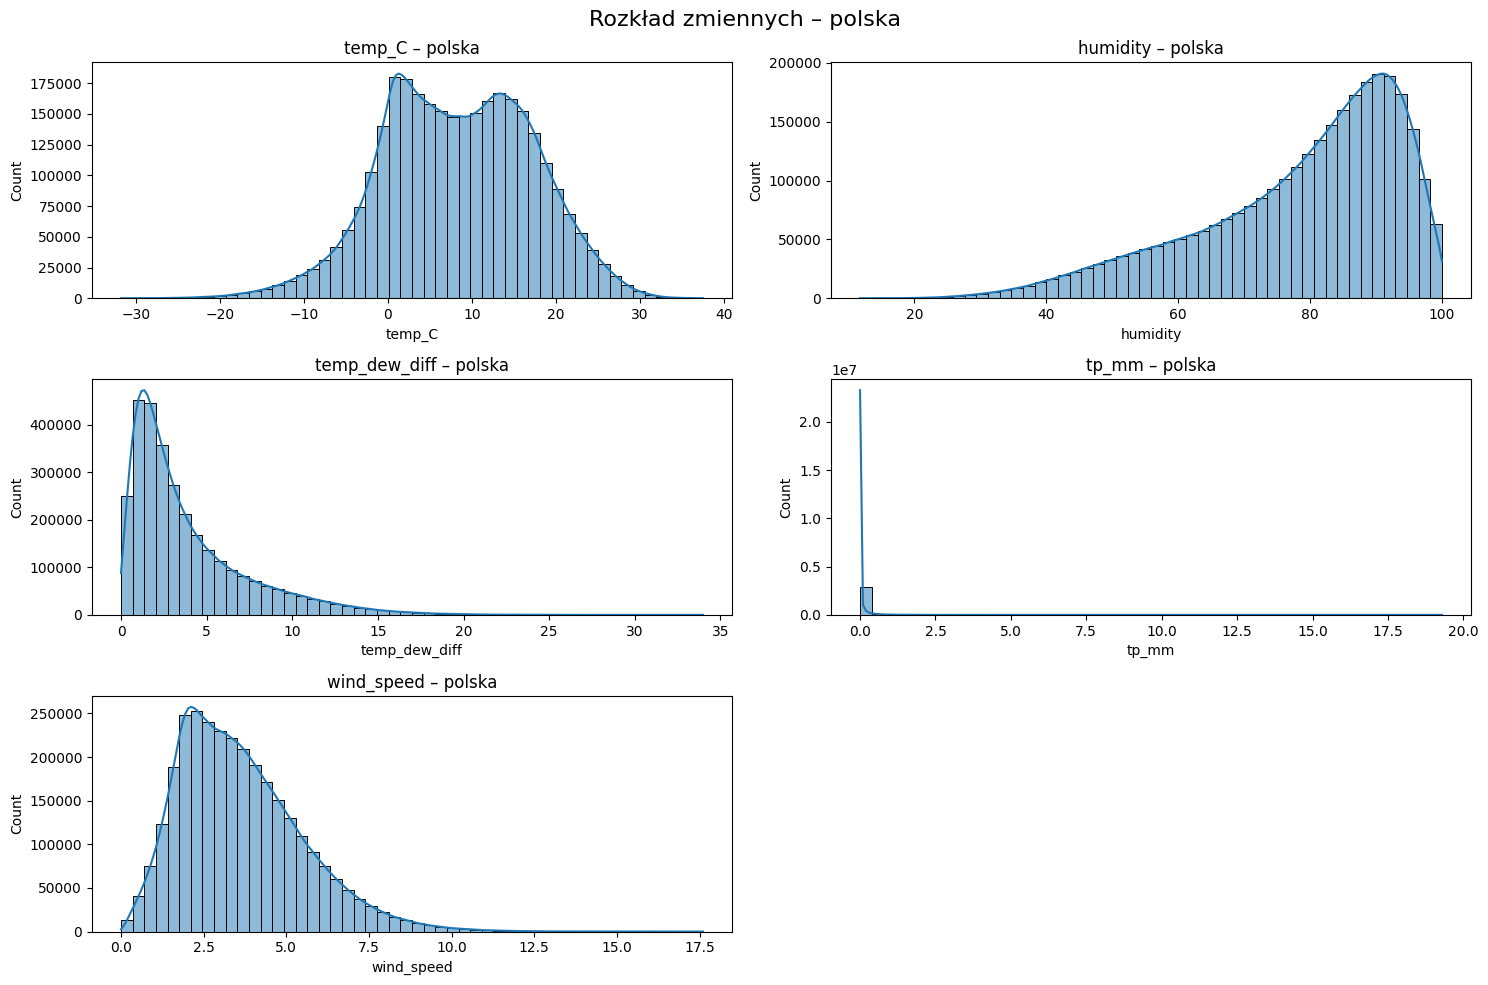

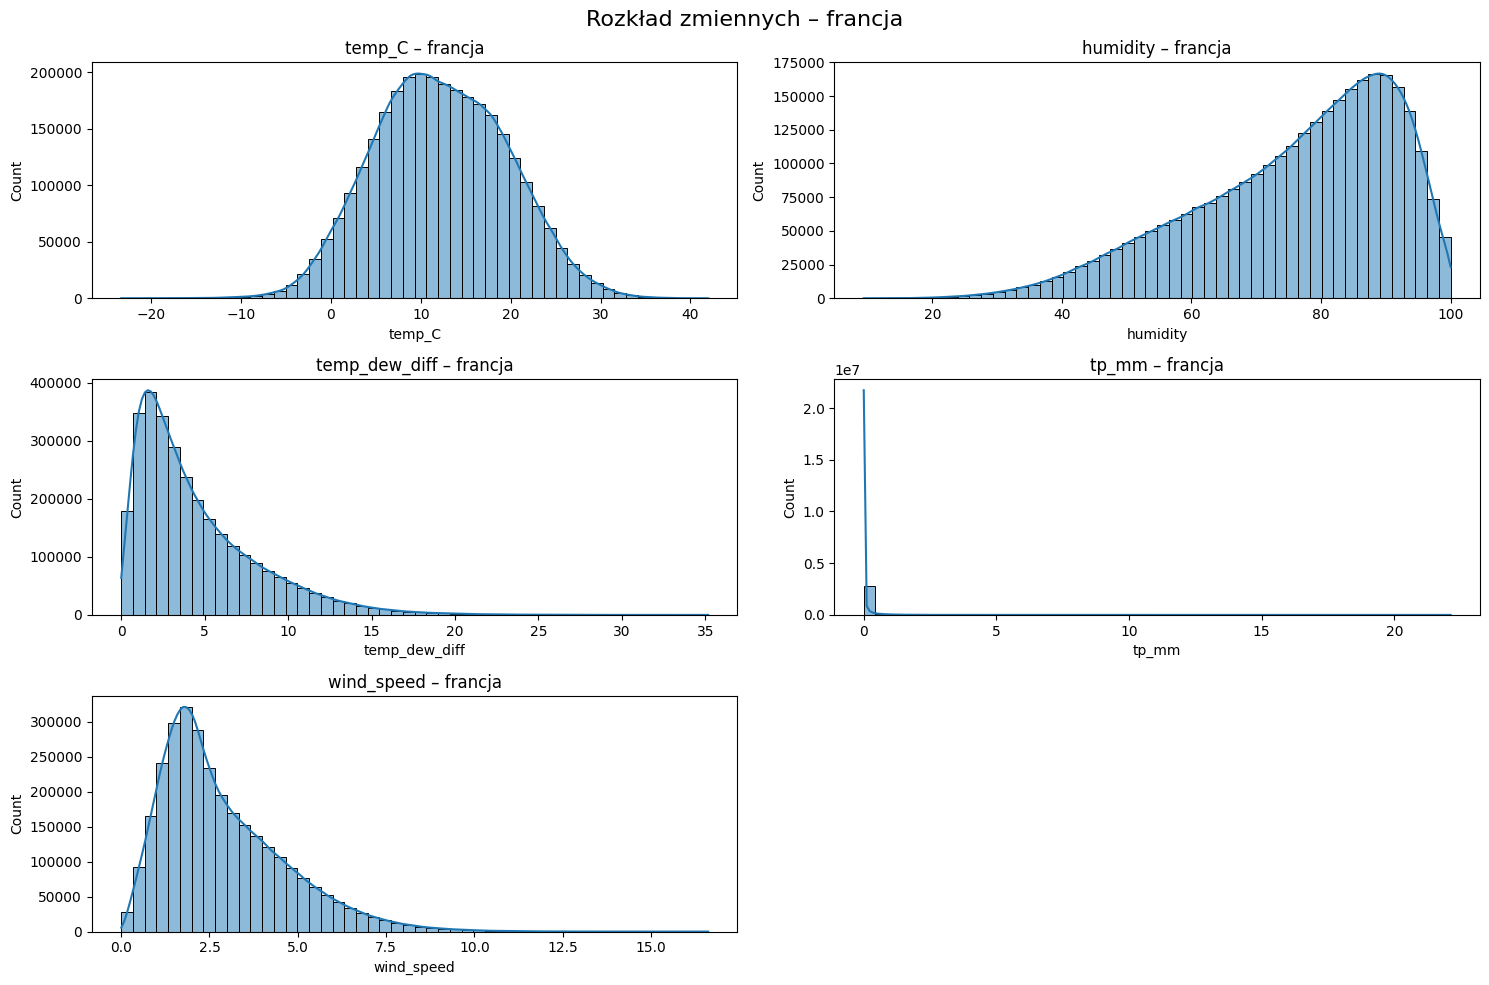

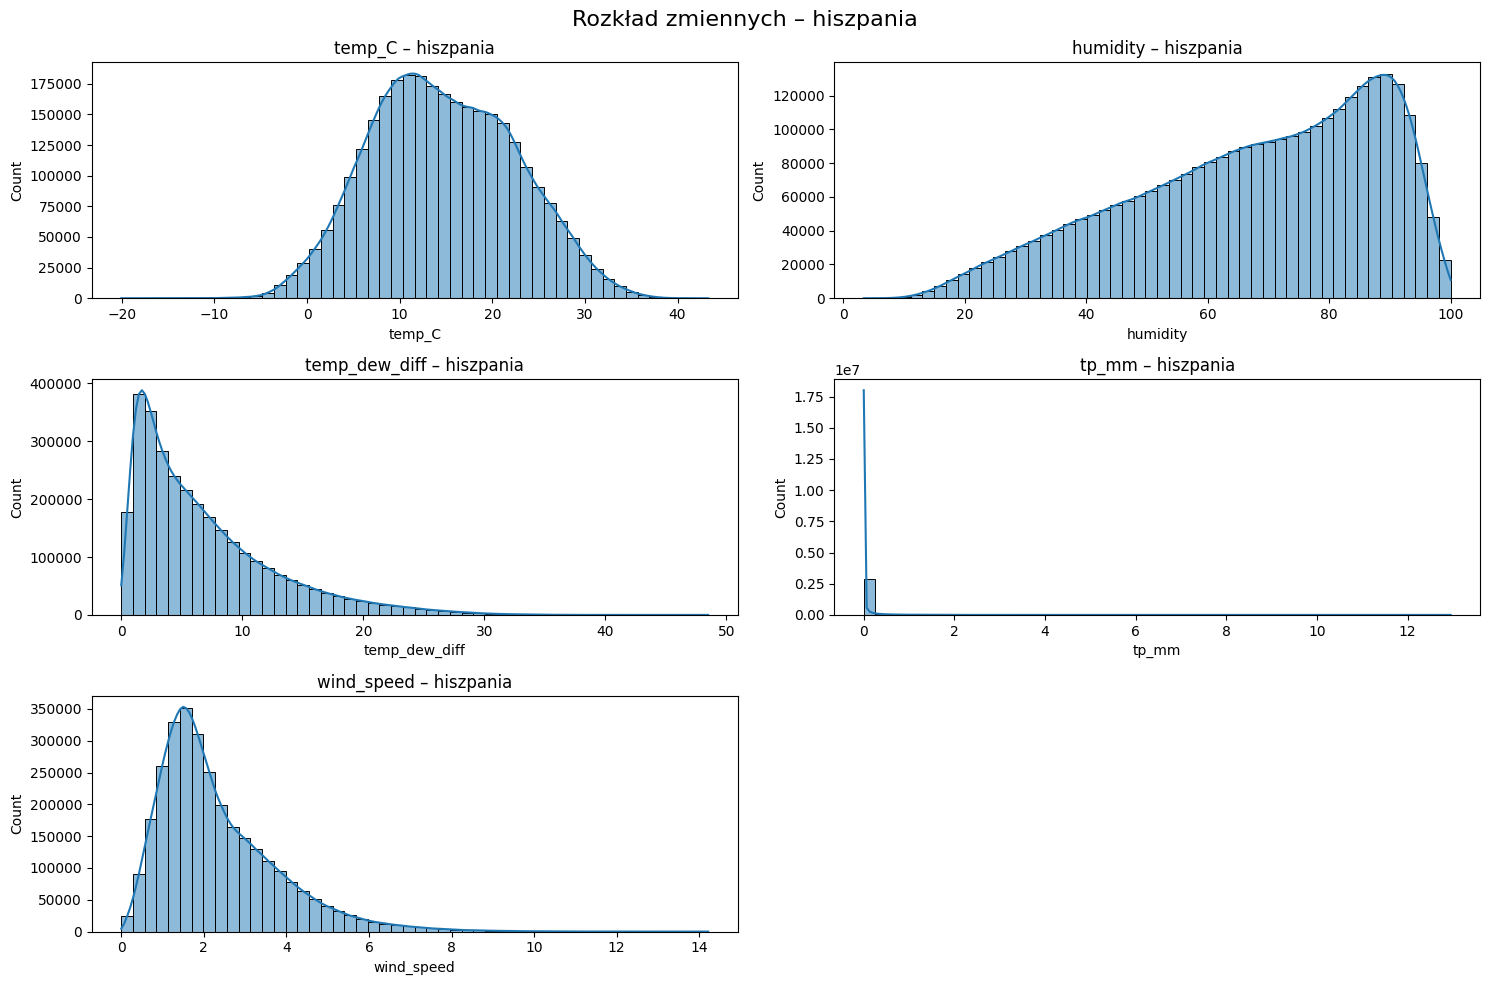

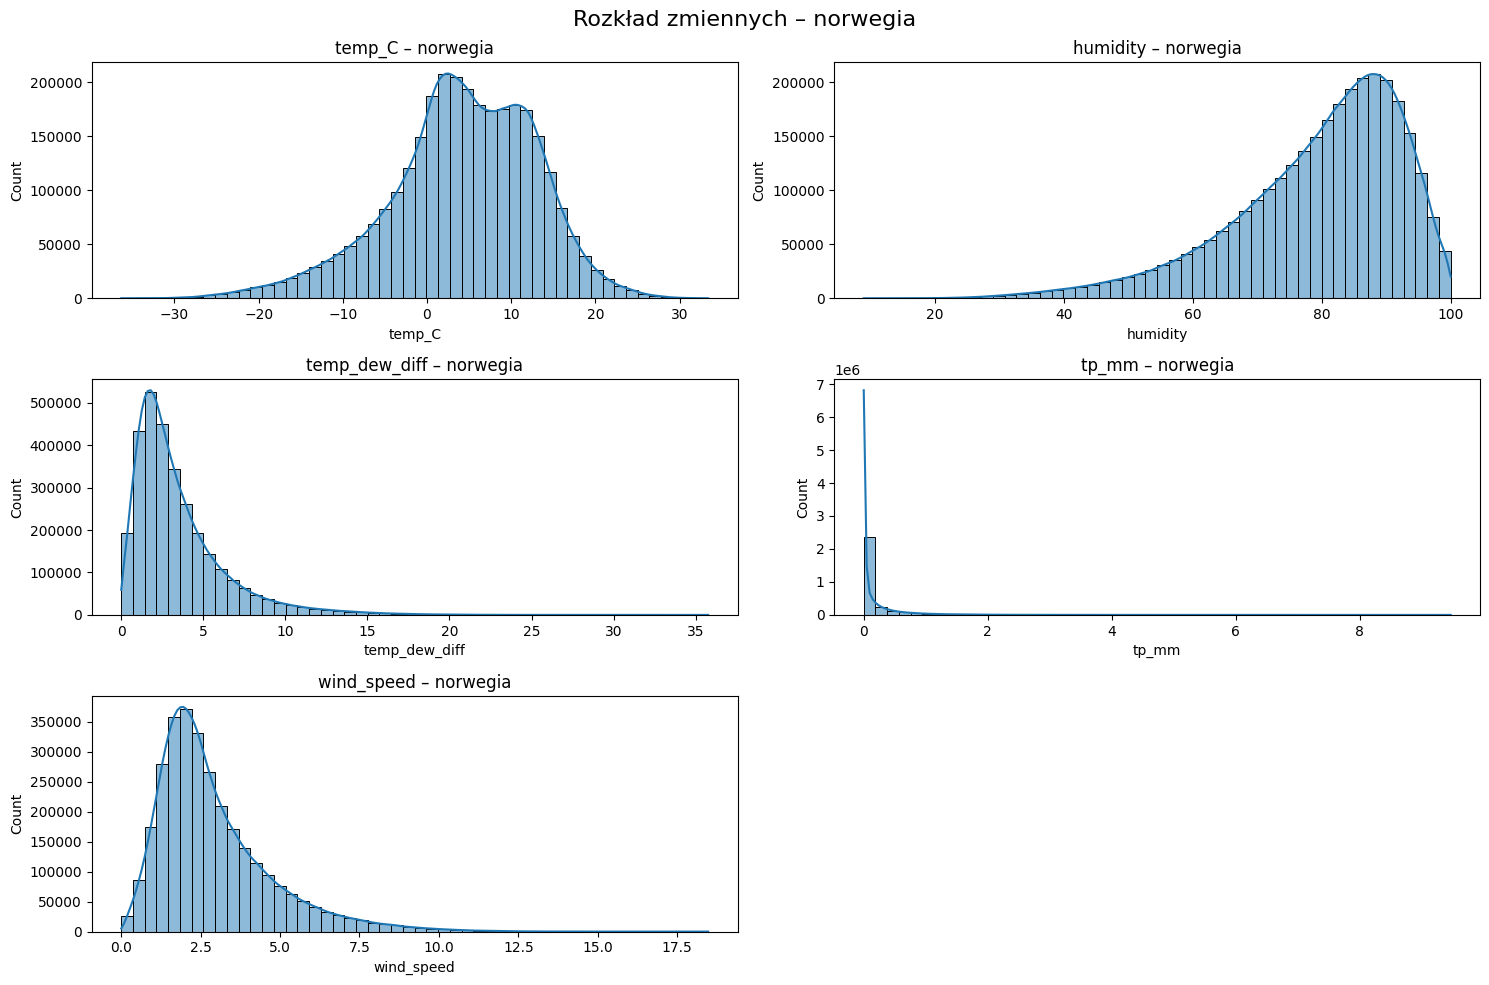

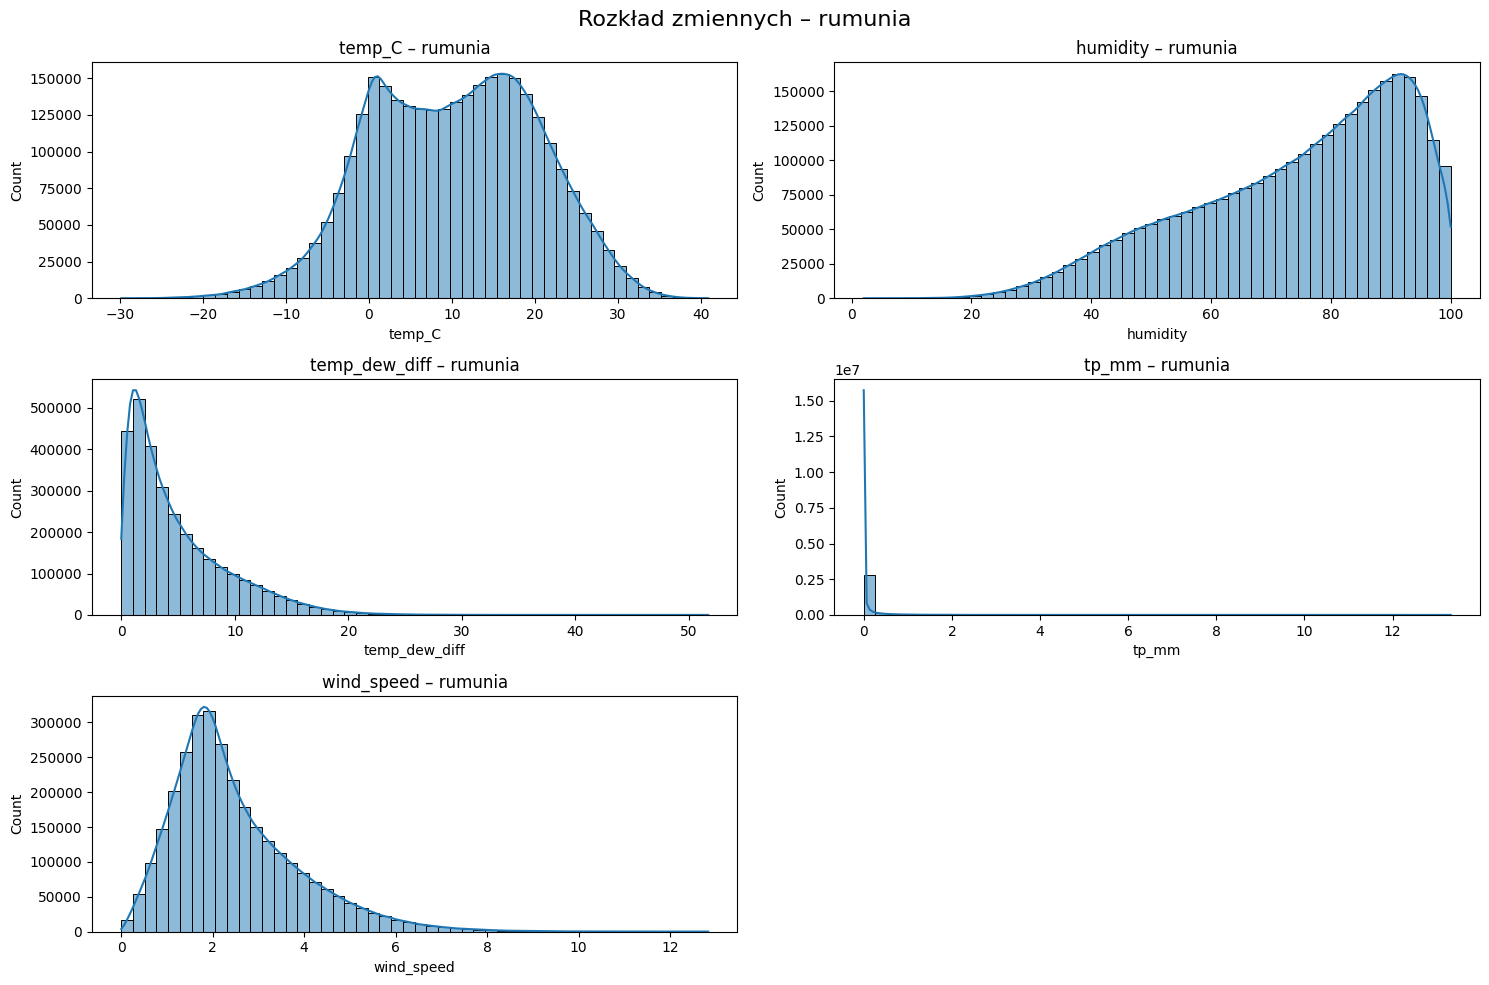

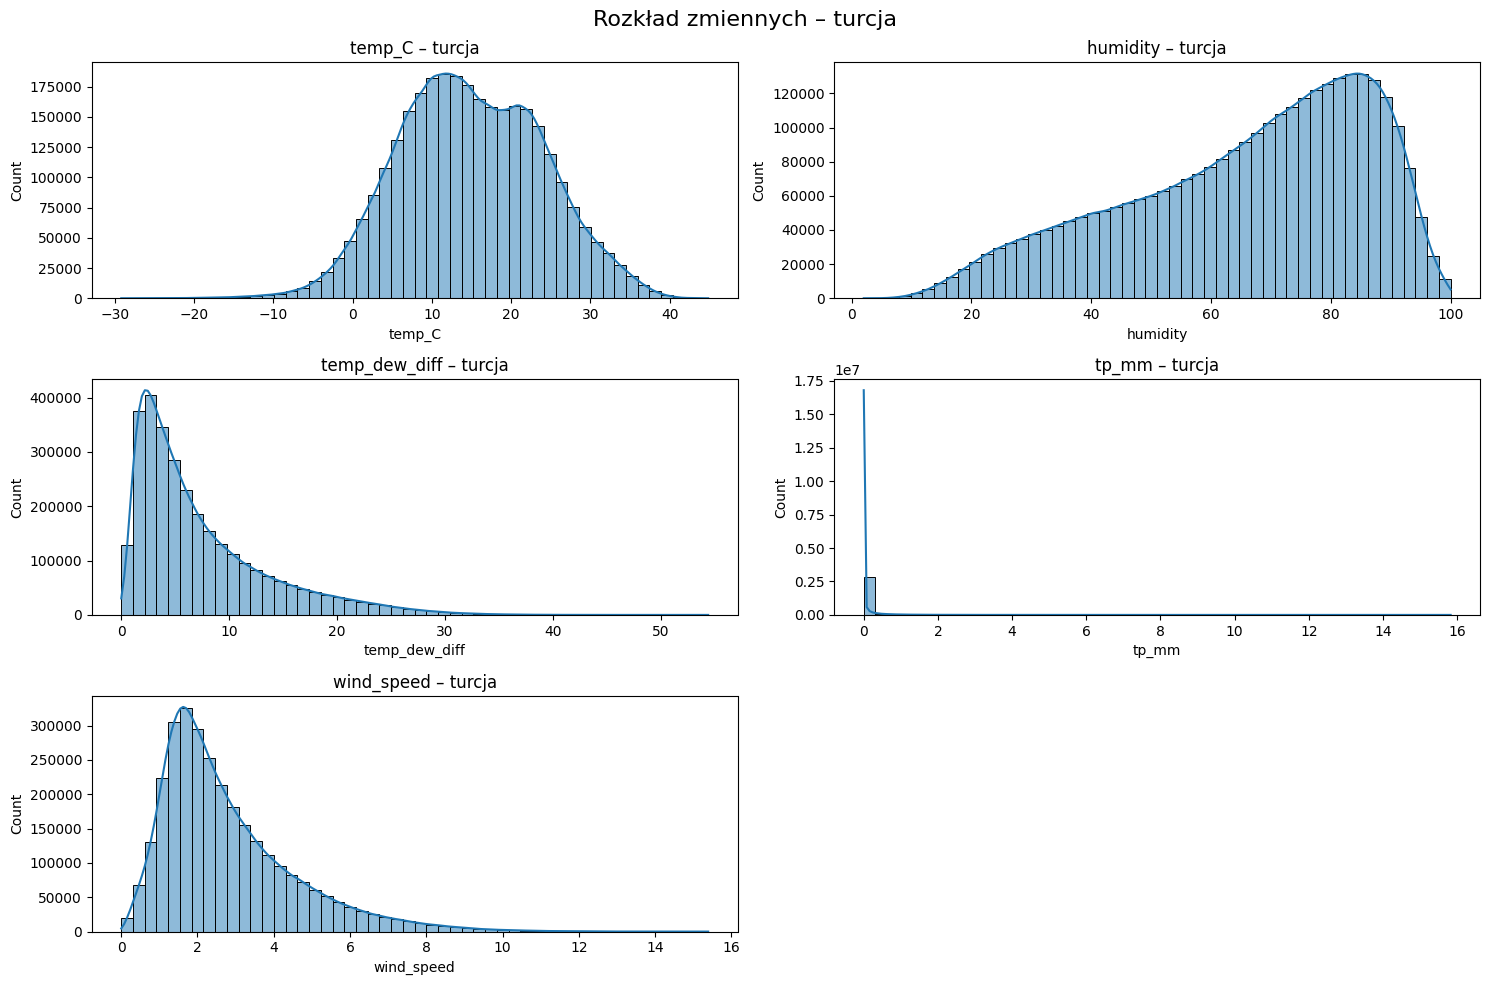

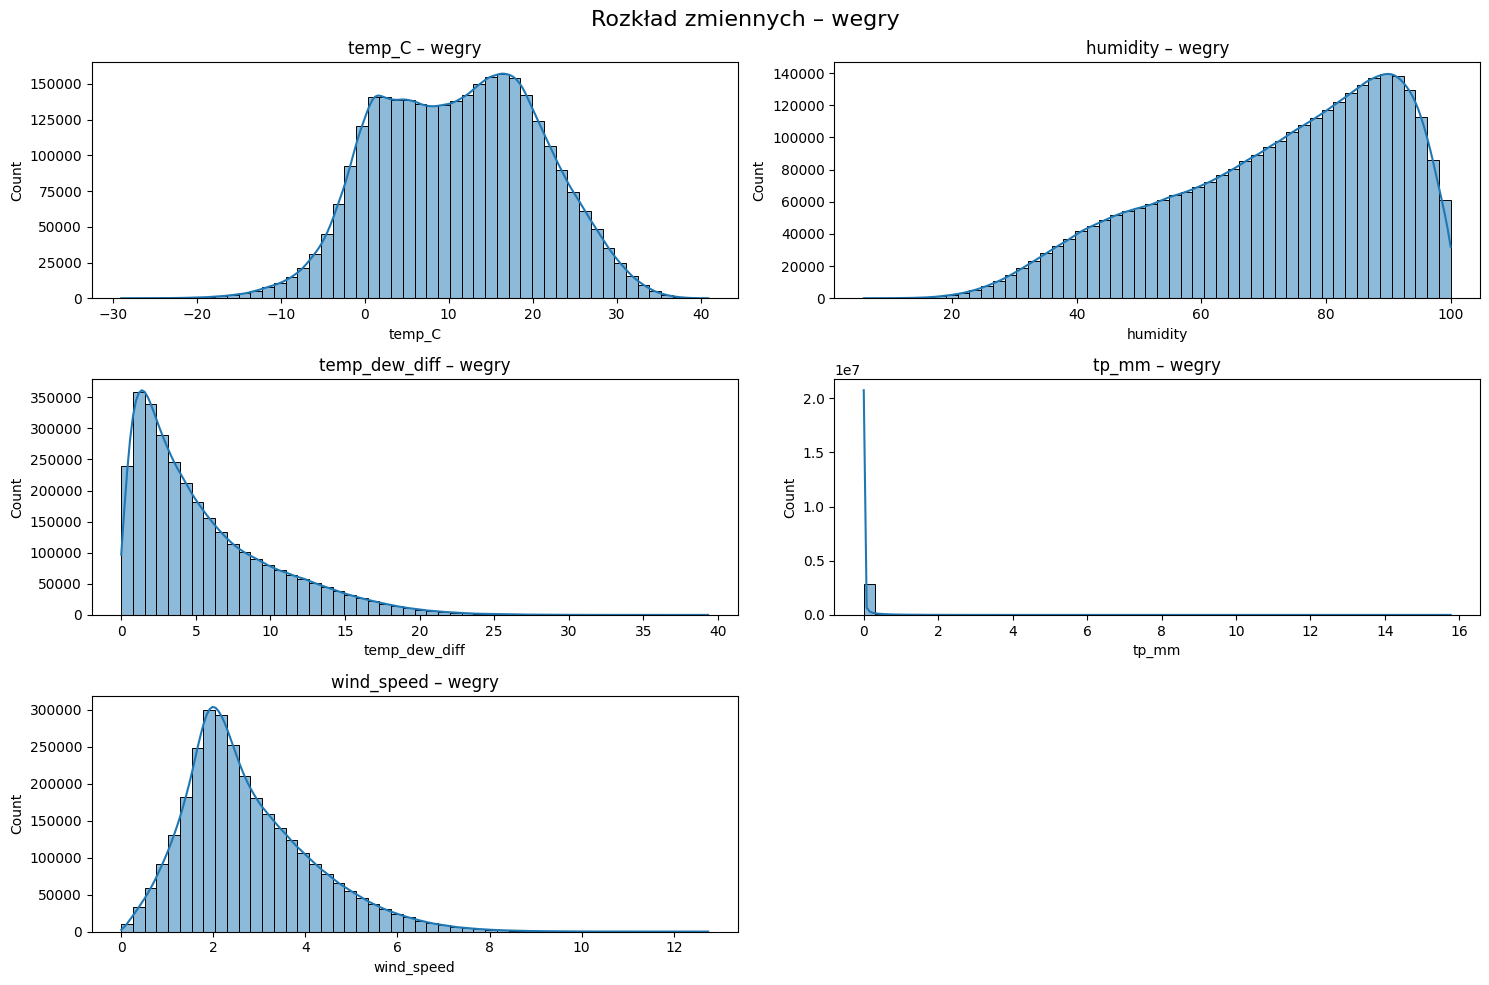

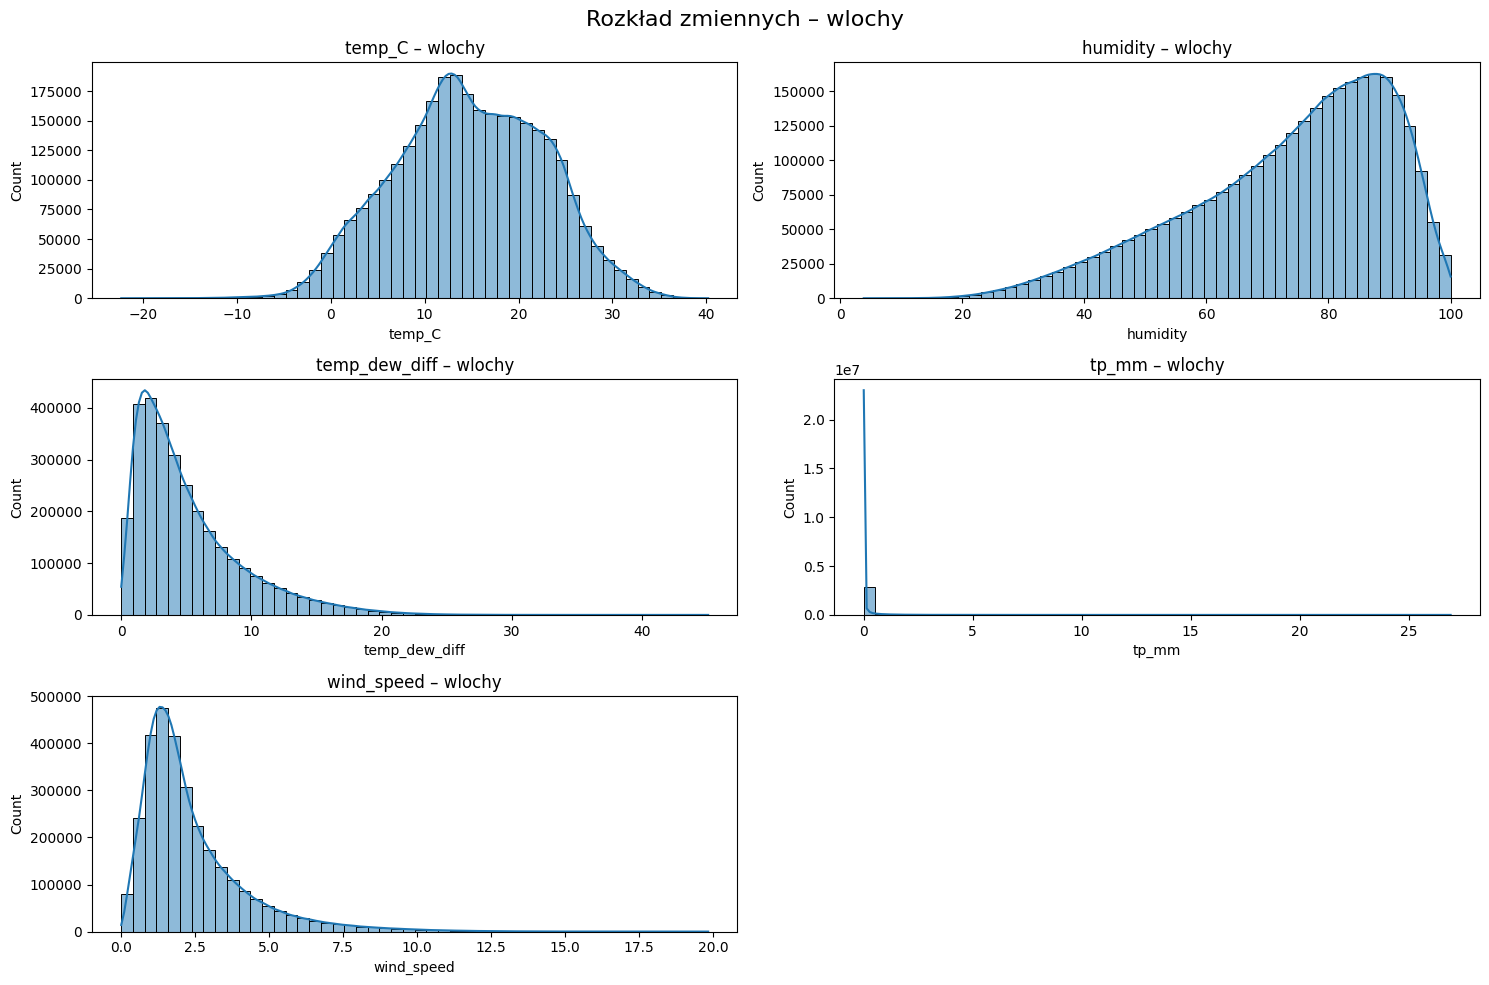

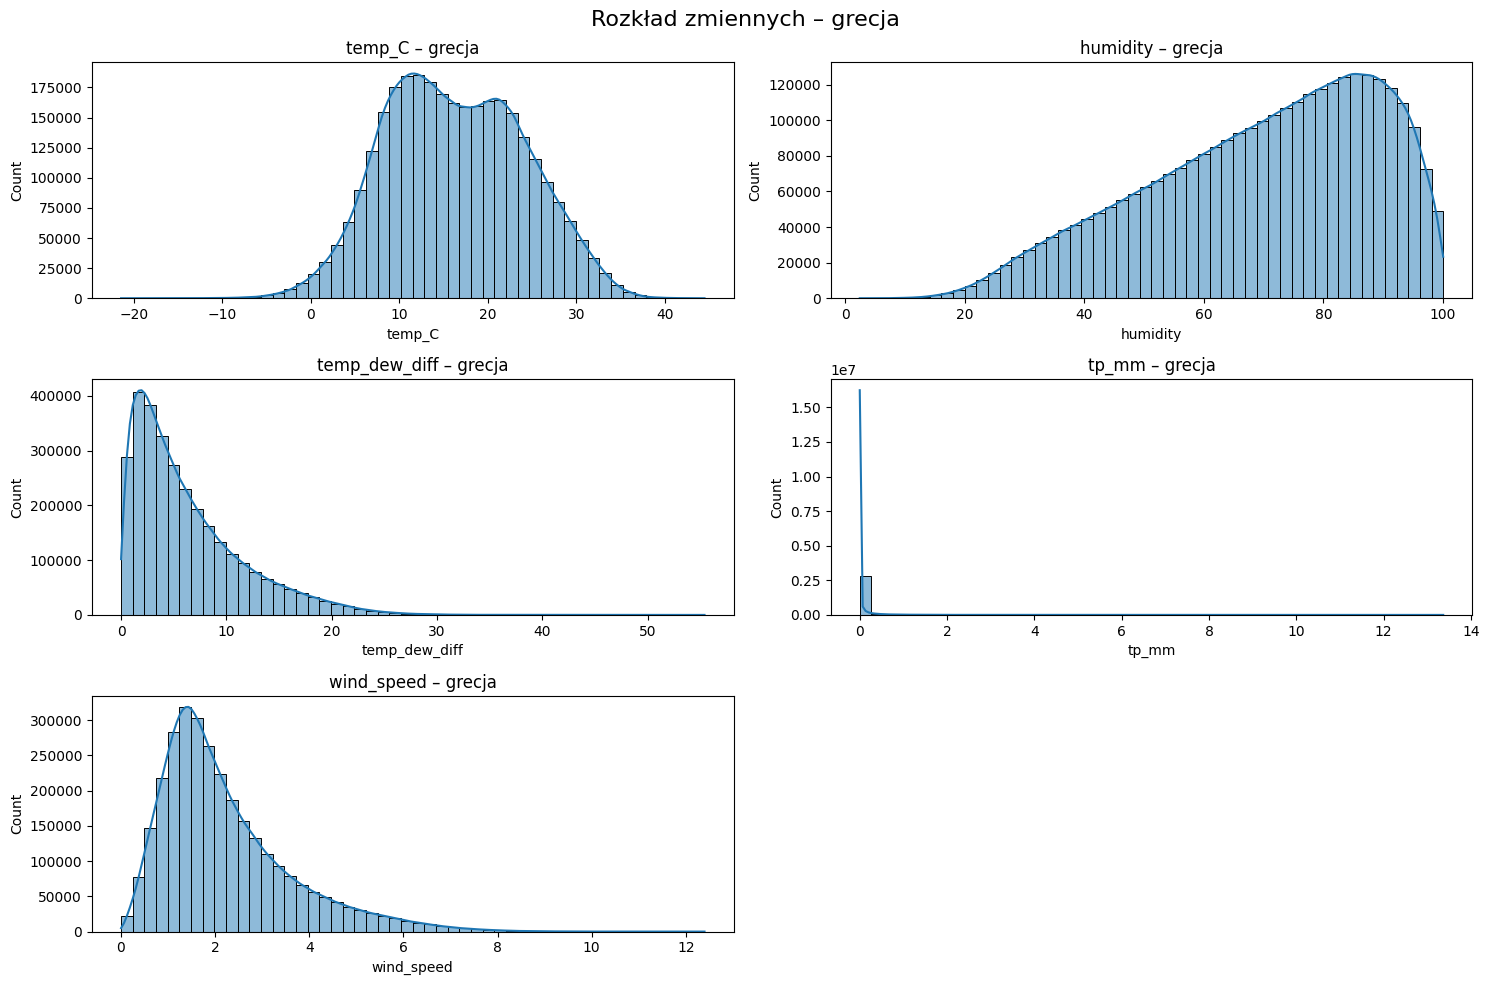

In [25]:
zmienne = ["temp_C", "humidity", "temp_dew_diff", "tp_mm", "wind_speed"]

for name, df in zip(
    ["polska","francja","hiszpania","norwegia","rumunia","turcja","wegry","wlochy","grecja"],
    lista_df
):
    plt.figure(figsize=(15, 10))
    
    for i, col in enumerate(zmienne):
        plt.subplot(3, 2, i+1)
        sns.histplot(df[col], bins=50, kde=True)
        plt.title(f"{col} – {name}")
    
    plt.suptitle(f"Rozkład zmiennych – {name}", fontsize=16)
    plt.tight_layout()
    plt.show()

Wykres rozkładu dla zmiennej humidity czyli wilgotnośc jest w każdym kraju lewoskośny, czyli oznacza to, ze większosć wartości jest wysokich.

Dla zmiennych wind_speed, temp_new_dif (różnica temp- punkt rosy) rozkład ich jest prawoskośny, oznacza to, że sporadycnzie pojawiają się duże wartości, większość wartości jest niskich. Czyli powietrze zazwyczaj jest umiarkowanie wilgotne, a waitr słaby. 

Ze względu na długi czas wykonywania się zapytania, wybrano analize rozkładu zmiennych dla miast w 1 kraju - mozliwość rozszerzenia już na dashboardzie!


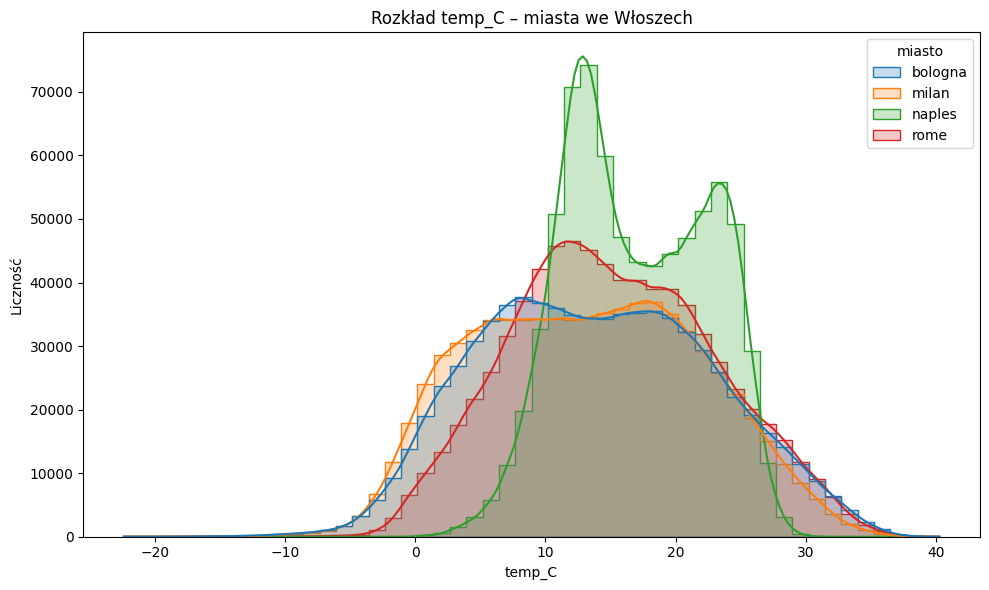

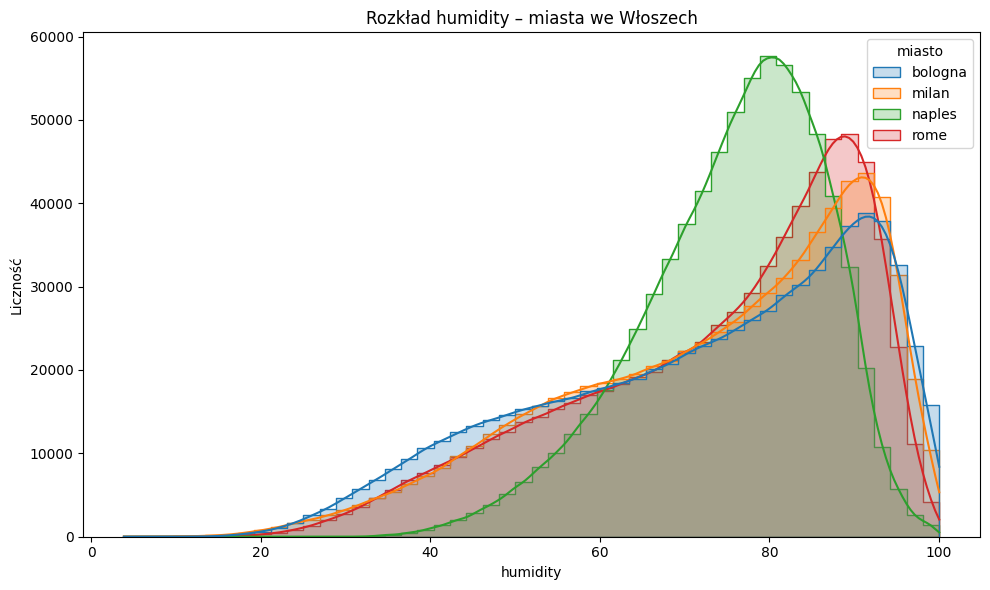

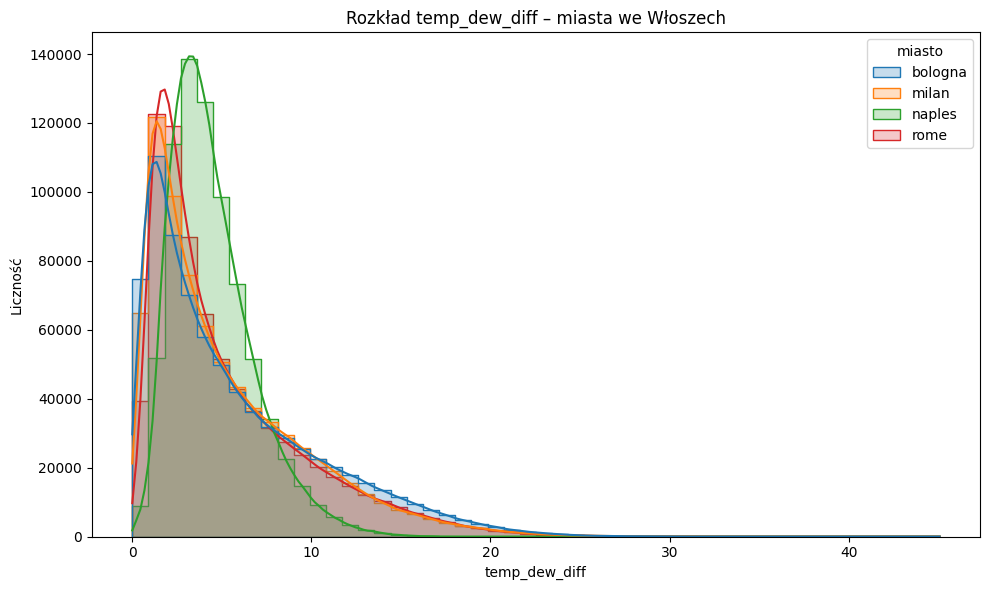

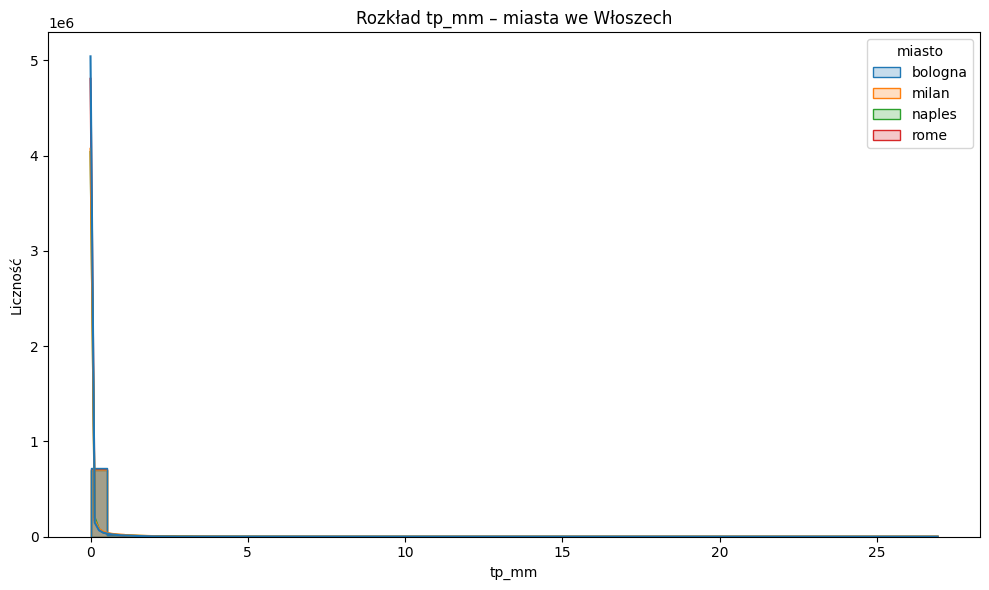

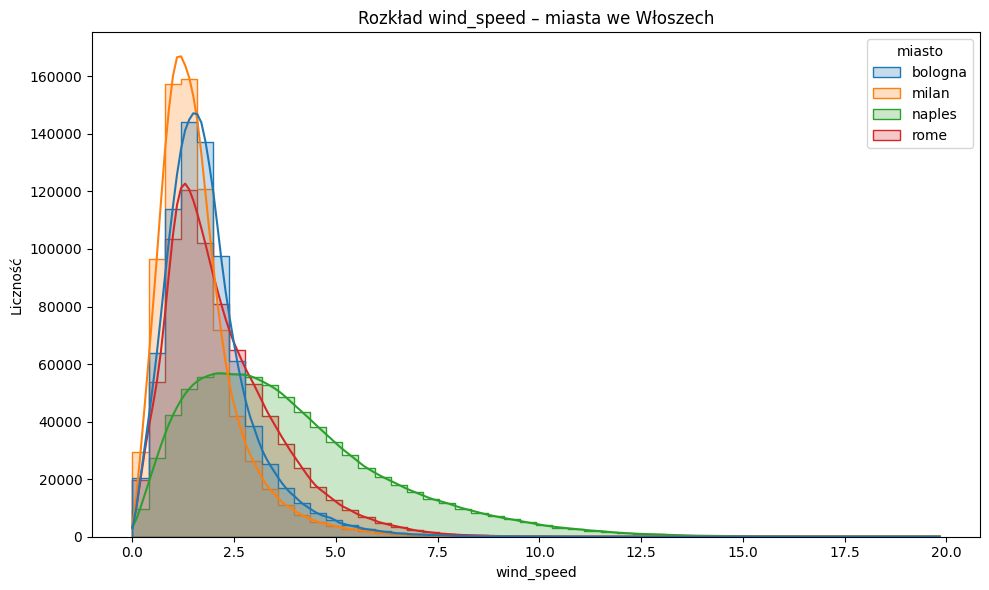

In [26]:
zmienne = ["temp_C", "humidity", "temp_dew_diff", "tp_mm", "wind_speed"]

for col in zmienne:
    plt.figure(figsize=(10,6))
    
    sns.histplot(
        data=df_wlochy,
        x=col,
        hue="miasto",
        bins=50,
        kde=True,
        element="step"
    )
    
    plt.title(f"Rozkład {col} – miasta we Włoszech")
    plt.xlabel(col)
    plt.ylabel("Liczność")
    
    plt.tight_layout()
    plt.show()

Widać, że miasto Naples wyróżnia się rozkładami zmiennych na tle innych (wind_speed, humidity, temp_C). Rozkład dla prędkości wiatru dla tego miasta jest najszerszy, czyli jest tam największa zmienność wiatru. Rozkład tempetarury dla Naples jest najwęższy, oraz ma dwa "piki", oznacza to że jest dwumdolany, czyli mamy dwie dominujące grupy temp (oznaka dwóch pór roku najczęściej).

**Dodanie cech czasu**

In [27]:
lista_df = [
    df_polska, df_francja, df_hiszpania, df_norwegia,
    df_rumunia, df_turcja, df_wegry, df_wlochy, df_grecja
]

for df in lista_df:
    df["year"] = df["valid_time"].dt.year
    df["month"] = df["valid_time"].dt.month
    df["day"] = df["valid_time"].dt.day

In [28]:
df_grecja.head()

,valid_time,u10,v10,d2m,t2m,tp,latitude,longitude,kraj,miasto,temp_C,dewpoint_C,tp_mm,wind_speed,temp_dew_diff,humidity,year,month,day
0,1940-01-01 00:00:00,0.196,-2.315,274.088,276.517,0.000,38.000,23.750,grecja,athens,3.367,0.938,0.000,2.324,2.429,84.108,1940,1,1
1,1940-01-01 01:00:00,0.498,-1.969,274.030,276.124,0.000,38.000,23.750,grecja,athens,2.974,0.880,0.000,2.031,2.094,86.114,1940,1,1
2,1940-01-01 02:00:00,0.615,-2.043,274.004,276.060,0.000,38.000,23.750,grecja,athens,2.910,0.854,0.000,2.133,2.057,86.340,1940,1,1
3,1940-01-01 03:00:00,0.412,-2.117,274.469,276.817,0.000,38.000,23.750,grecja,athens,3.667,1.319,0.000,2.156,2.347,84.637,1940,1,1
4,1940-01-01 04:00:00,0.372,-2.289,274.388,276.812,0.000,38.000,23.750,grecja,athens,3.662,1.238,0.000,2.319,2.424,84.173,1940,1,1


**Zapis datasetu po konwersji i dodaniu nowych zmiennych**

In [31]:
import pyarrow as pa
import pyarrow.parquet as pq

kolumny = [
    "valid_time",
    "latitude",
    "longitude",
    "kraj",
    "miasto",
    "temp_C",
    "dewpoint_C",
    "humidity",
    "temp_dew_diff",
    "tp_mm",
    "wind_speed",
    "year",
    "month",
    "day"
]

sciezka_out = "era5_europa_raw_1940_2026.parquet"

writer = None

for df in lista_df:
    df_part = df[kolumny].copy()

    # zmniejszenie typów = mniej RAM
    df_part["latitude"] = df_part["latitude"].astype("float32")
    df_part["longitude"] = df_part["longitude"].astype("float32")
    df_part["temp_C"] = df_part["temp_C"].astype("float32")
    df_part["dewpoint_C"] = df_part["dewpoint_C"].astype("float32")
    df_part["humidity"] = df_part["humidity"].astype("float32")
    df_part["temp_dew_diff"] = df_part["temp_dew_diff"].astype("float32")
    df_part["tp_mm"] = df_part["tp_mm"].astype("float32")
    df_part["wind_speed"] = df_part["wind_speed"].astype("float32")
    df_part["year"] = df_part["year"].astype("int16")
    df_part["month"] = df_part["month"].astype("int8")
    df_part["day"] = df_part["day"].astype("int8")

    table = pa.Table.from_pandas(df_part)

    if writer is None:
        writer = pq.ParquetWriter(sciezka_out, table.schema)

    writer.write_table(table)

if writer:
    writer.close()

print("Zapisano plik Parquet.")

Zapisano plik Parquet.


In [32]:
df_part.head()

,valid_time,latitude,longitude,kraj,miasto,temp_C,dewpoint_C,humidity,temp_dew_diff,tp_mm,wind_speed,year,month,day
0,1940-01-01 00:00:00,38.000,23.750,grecja,athens,3.367,0.938,84.108,2.429,0.000,2.324,1940,1,1
1,1940-01-01 01:00:00,38.000,23.750,grecja,athens,2.974,0.880,86.114,2.094,0.000,2.031,1940,1,1
2,1940-01-01 02:00:00,38.000,23.750,grecja,athens,2.910,0.854,86.340,2.057,0.000,2.133,1940,1,1
3,1940-01-01 03:00:00,38.000,23.750,grecja,athens,3.667,1.319,84.637,2.347,0.000,2.156,1940,1,1
4,1940-01-01 04:00:00,38.000,23.750,grecja,athens,3.662,1.238,84.173,2.424,0.000,2.319,1940,1,1


In [30]:
!pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/27.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/27.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/27.3 MB 812.7 kB/s eta 0:00:34
   ---------------------------------------- 0.1/27.3 MB 1.1 MB/s eta 0:00:25
   ---------------------------------------- 0.3/27.3 MB 2.0 MB/s eta 0:00:14
   - -------------------------------------- 0.8/27.3 MB 3.8 MB/s eta 0:00:07
   -- ------------------------------------- 1.7/27.3 MB 6.9 MB/s eta 0:00:04
   --- ------------------------------------ 2.3/27.3 MB 7.6 MB/s eta 0:00:04
   ------ --------------------------------- 4.4/27.3 MB 12.7 MB/s eta 0:00:02
   -------- ------------------------------- 5.9/27.3 MB 15.1 MB/s eta 0:00:02
   ----------- ---------------------------- 7.6/27.3 MB 17.9 MB/s eta 0:00:02
   ------------- -------------------------- 9.0/27.3 MB 19.2 MB/s eta 0:00:01
   ---


[notice] A new release of pip is available: 24.0 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip
